# TritFlow — Code-a-Chip ISSCC 2027

| Author | Affiliation | Email |
|---|---|---|
| [AUTHOR_NAME] | [AFFILIATION] | [EMAIL] |

Team: [TEAM_NAME_OR_INDIVIDUAL]. Representative: [DESIGNATED_REPRESENTATIVE].

**Apache-2.0. Identity/asset-rights confirmations remain in README.**

TritFlow is an open-source, notebook-driven flow that makes balanced-ternary
circuit design inspectable from a Verilog-like description to physical layout
and extracted transistor simulation. Using the OpenSUSI TR-1um PDK, it connects
ternary-safe synthesis, a three-rail standard-cell library, placement and
two-layer routing, official design-rule and connectivity checks, and ngspice
verification against independent arithmetic references. The notebook begins
with a complete adder, then connects gate truth tables and historical
schematics to cell characterization, measured self-loading, mapping decisions,
physical geometry, and pre/post-layout settling. Published experiments expose
adder scaling and an output-load failure boundary, while editable examples
let readers test their own circuits through the same interfaces. Saved figures
and generated tables support review without execution; pinned source/runtime
setup and content-checked caches support reproduction. Coverage, operating
conditions, convergence aids, static-current costs and parasitic-model limits
are stated explicitly. The project teaches a reproducible design methodology
without claiming a performance advantage over binary CMOS or measured silicon.

Saved outputs were executed locally, with static PNG figures for reading without running. Animation stills show their initial frame. Machine paths are normalized; numerical results are unchanged. The original source cells and bootstrap are preserved; rerun them for interactive figures. Clean Colab installation remains unverified/postponed.

**Release TODO before filing:** the default `colab-v0` release does not match this submitted notebook or could not be verified. The integrator must publish a corresponding immutable source tag and configure `TRITFLOW_REF` before the bootstrap; the bootstrap itself is unchanged. See `build-info.json` for the checked commit/missing helpers. Saved outputs remain readable offline; the existing badge is not a verified reproducer of this captured version.

<details><summary>Tool versions observed at packaging (runtime pins are in the bootstrap)</summary>

```json
{
  "numpy": "2.4.3",
  "scipy": "1.17.1",
  "plotly": "7.1.0",
  "klayout": "0.30.6",
  "lark": "1.3.1",
  "matplotlib": "3.10.8",
  "Pillow": "10.2.0",
  "nbformat": "5.10.4",
  "nbclient": "0.10.4",
  "kaleido": "1.5.0",
  "choreographer": "1.4.0",
  "CairoSVG": "2.8.2",
  "python": "3.12.3",
  "ngspice": "ngspice-46+",
  "klayout_binary": "KLayout 0.30.9",
  "static_export_browser": "Google Chrome 152.0.7977.64"
}
```
</details>


# TritFlow: balanced-ternary HDL to GDS on OpenSUSI TR-1um

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PenguinEino/tritflow/blob/colab-v0/notebook/tritflow_tr1um.ipynb)

Draft for IEEE SSCS Code-a-Chip, ISSCC 2027. Audience: designers familiar with
CMOS, synthesis, P&R and SPICE. We follow a real three-rail circuit through the
flow, separating logical equivalence, physical connectivity and nominal analog
settling. Coverage and conditions are generated beside each result.

Colab shallow-clones [TritFlow](https://github.com/PenguinEino/tritflow) at
`colab-v0` into `/content/tritflow`, prints the resolved commit and installs
the package editably beside its committed cell/example/figure assets. Set
`TRITFLOW_REF` before the first cell to select another tag or branch. An existing
Colab checkout must match the requested ref and have no tracked edits.
**Release TODO — integrator:** create the `colab-v0` tag after committing this
notebook. Fresh Colab execution and the install-inclusive ten-minute budget
remain unverified.

The default run starts with a small adder, then closes the loop on every shared
example and one selected circuit. Coverage is reported beside each experiment.
Heavy stages use content-keyed JSON caches; `TRITFLOW_EXTENDED=1` enables extra
load/routing views. Cached reports are identified as cache hits and their
artifact hashes are checked. A cache is evidence of the recorded run, not a new
DRC/LVS execution. Clear `build/notebook/cache` to force recomputation.


In [2]:
import os, sys, json, time, hashlib, subprocess, importlib.util
from pathlib import Path
started = time.monotonic()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
SOURCE_URL = "https://github.com/PenguinEino/tritflow.git"
SOURCE_REF = os.environ.get("TRITFLOW_REF", "colab-v0")
def source_git(*args):
    return subprocess.check_output(["git", "-C", str(ROOT), *args], text=True).strip()
if IN_COLAB:
    ROOT = Path("/content/tritflow")
    if not SOURCE_REF or SOURCE_REF.startswith("-") or any(c.isspace() for c in SOURCE_REF):
        raise ValueError("TRITFLOW_REF must name a Git tag or branch")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--single-branch", "--branch", SOURCE_REF,
                        SOURCE_URL, str(ROOT)], check=True)
    if not (ROOT/".git").is_dir():
        raise RuntimeError("/content/tritflow must be a git clone; use a fresh Colab runtime")
    if source_git("remote", "get-url", "origin").removesuffix(".git") != SOURCE_URL.removesuffix(".git"):
        raise RuntimeError("existing checkout has a different origin; use a fresh Colab runtime")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}")
    requested_commit = source_git("rev-parse", "--verify", SOURCE_REF+"^{commit}")
    if SOURCE_COMMIT != requested_commit or source_git("status", "--porcelain", "--untracked-files=no"):
        raise RuntimeError("existing checkout differs from TRITFLOW_REF; use a fresh Colab runtime")
    print(f"Source: {SOURCE_URL} ref={SOURCE_REF} commit={SOURCE_COMMIT}", flush=True)
    runtime = ROOT/"notebook/runtime.json"
    if not runtime.is_file():
        subprocess.run(["bash", str(ROOT/"notebook/colab_setup.sh"), "--source", str(ROOT)], check=True)
    os.environ.update(json.loads(runtime.read_text()))
else:
    candidates = [Path(os.environ.get("TRITFLOW_ROOT", ".")), Path.cwd(), Path.cwd().parent]
    ROOT = next((p.resolve() for p in candidates if (p/"pyproject.toml").is_file()
                 and (p/"tritflow").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("run locally from the full checkout or set TRITFLOW_ROOT")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}") if (ROOT/".git").exists() else "tracked-tree export (no .git)"
    print(f"Source: {ROOT} commit={SOURCE_COMMIT}")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/"notebook"))
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")


Source: $TRITFLOW_ROOT commit=23e36f15f9432507a4403512d0e0159d7980a6ed


'offscreen'

In [3]:
import numpy as np
from IPython.display import display, HTML, Image
from tritflow import flow, CELLS_DIR, PDK_ROOT, PASS_BAND, TRIT_VOLTS
from tritflow.sim import dc_transfer, input_vectors, subcircuits
from tritflow.viz.graph import color_nets, gate_graph, truth_table_html
from tritflow.viz.waves import waveform_figure, transfer_figure
from tritflow.viz.layout import render_gds, layout_figure, placement_animation, routing_progress
from cache import Cache, runtime_fingerprint
from schematics import schematic_gallery
from experiments import (complete_design, experiment_artifacts, assert_experiment,
                         load_edited, verify_publication_sources)
EXTENDED = os.environ.get("TRITFLOW_EXTENDED", "0") == "1"
BUILD = Path(os.environ.get("TRITFLOW_NOTEBOOK_BUILD", ROOT/"build/notebook")).resolve()
cache = Cache(BUILD/"cache", runtime_fingerprint(ROOT, PDK_ROOT))
def show(figure):
    if os.environ.get("TRITFLOW_NOTEBOOK_HEADLESS") == "1":
        figure.to_json()  # still validate every figure during local execution
    else:
        display(figure)
def table(rows):
    from html import escape
    display(HTML("<div style='overflow-x:auto'><table>"+"".join("<tr>"+"".join("<td style='padding:.3em .8em'>"+
        escape(str(v))+"</td>" for v in row)+"</tr>" for row in rows)+"</table></div>"))


## 0. Start with the complete adder flow

A trit is −1, 0 or +1, represented by −5, 0 or +5 V. It is distinct from
Verilog's four-state logic. We first build a two-trit ripple adder from HDL,
route real cells into GDS, check DRC/LVS, and simulate extracted devices plus
estimated wire capacitance. Integer arithmetic supplies an independent oracle.
The logical test is exhaustive. The generated coverage table distinguishes it
from the representative analog sequence, which includes initialization and
return. The analog sequence covers neither all directed transitions nor PVT.


Running: adder2-complete


Logical input states (exhaustive),243
Analog states / unique states,6 / 5
Analog transitions (selected / possible),5 / 58806
Configured rails (trit: V),"{-1: -5.0, 0: 0.0, 1: 5.0}"
Level acceptance band (V),0.5
Nominal temperature (°C),27
Output load (fF),100.0
Hold / ramp / max step (ns),"[1000.0, 1.0, 2.0]"
Cells,"{'INV': 10, 'NANY': 22}"
GDS,$OUTPUTDIR/flow/adder2_demo/adder2_demo.gds
Die dimensions (µm),"[1254.0, 1206.0]"


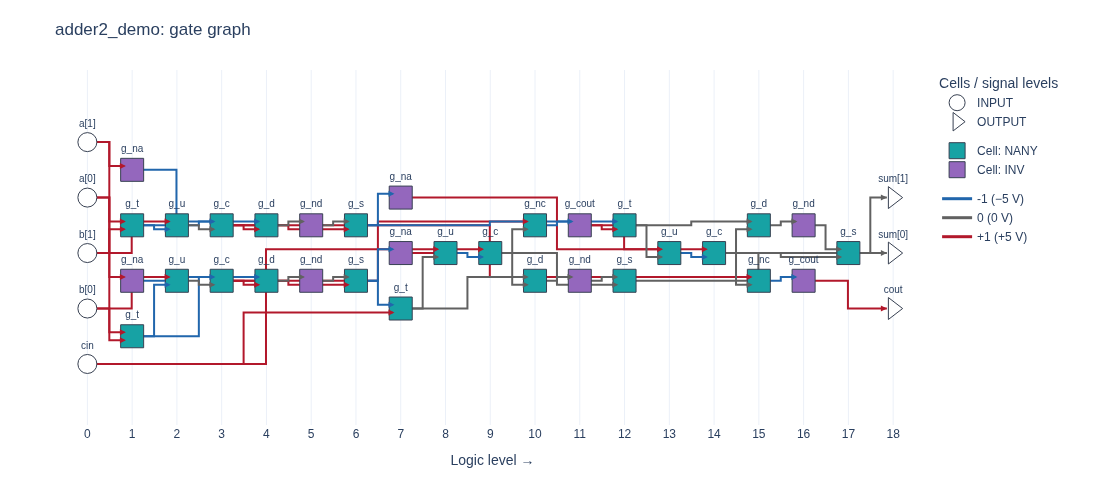

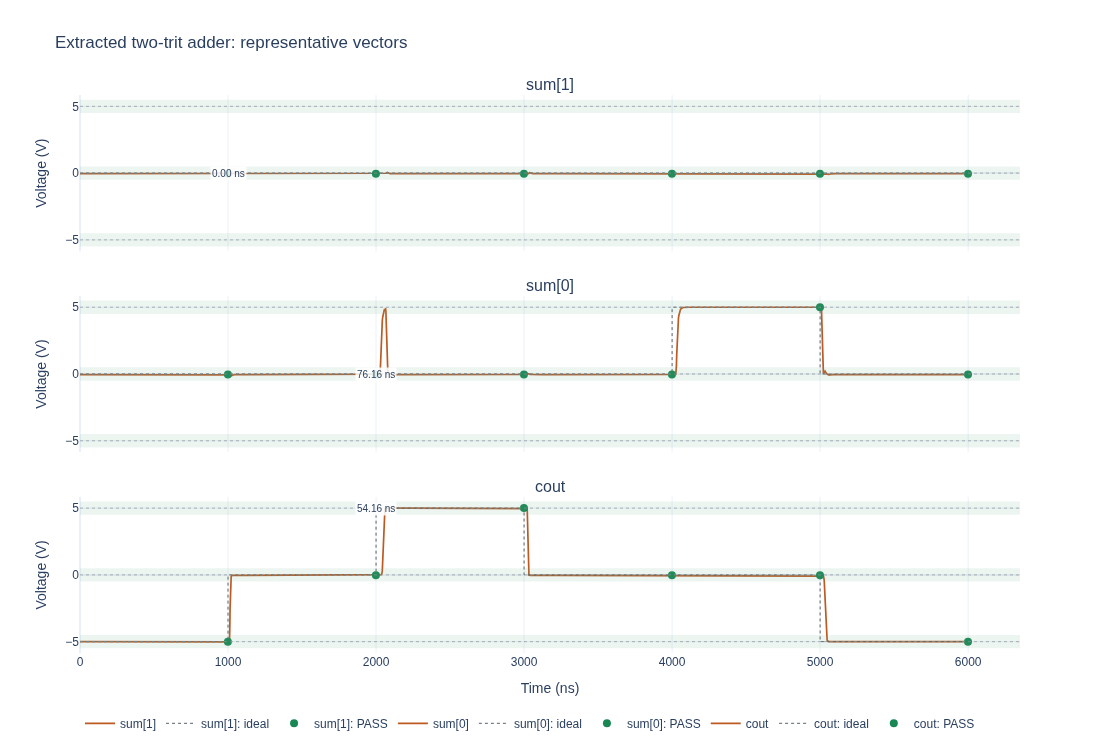

Running: adder2-raster


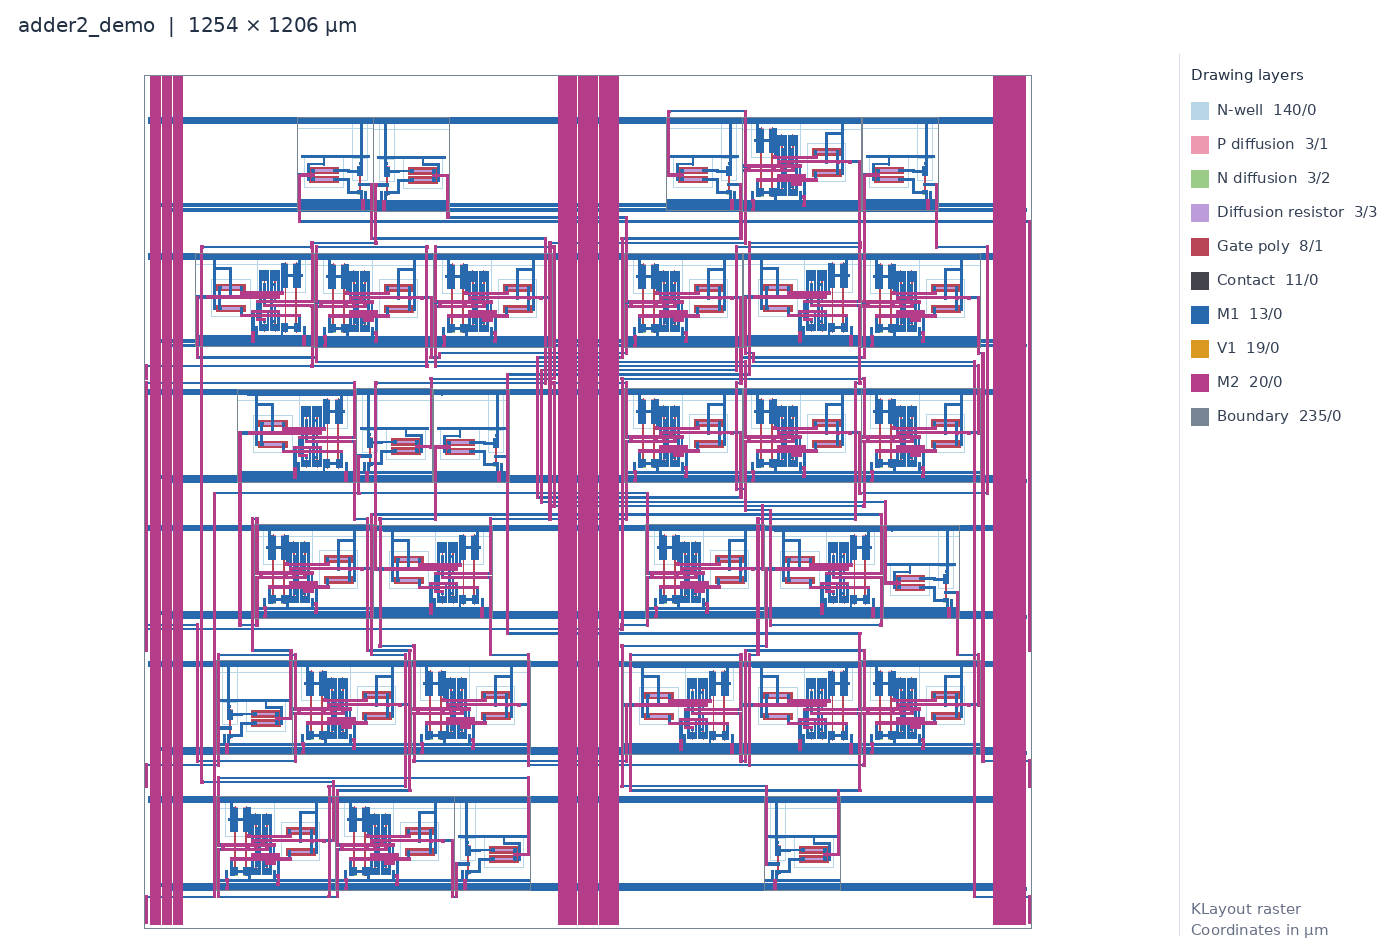

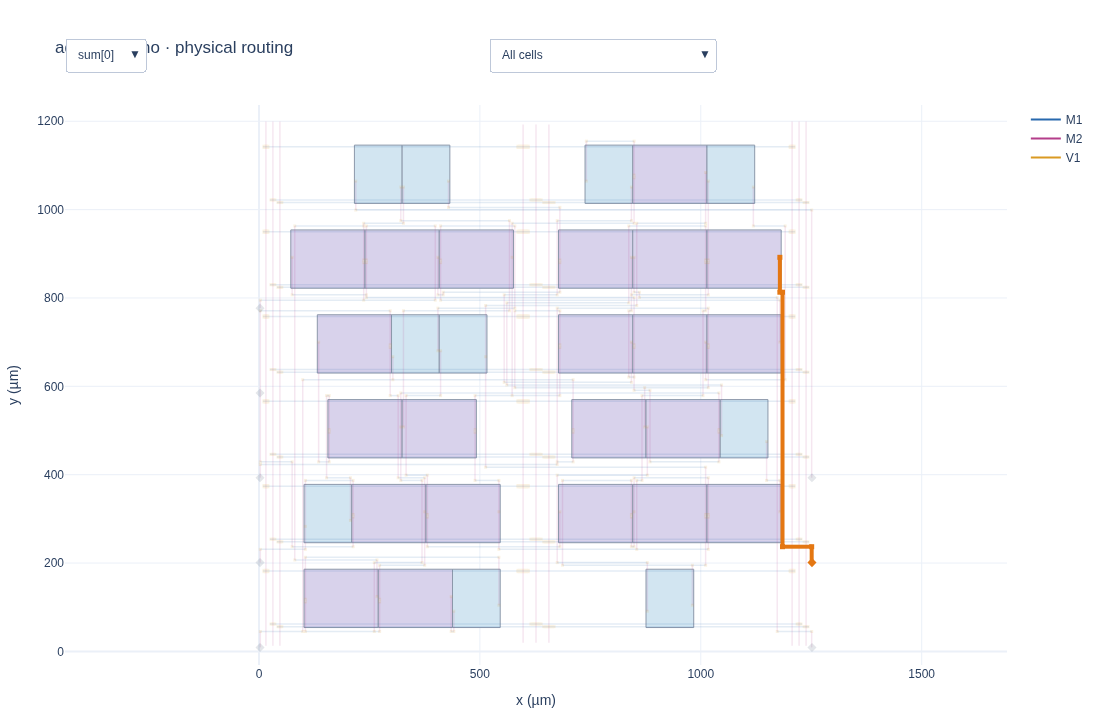

In [4]:
d = flow.load(ROOT/"examples/adder.tv", "adder", {"N": 2})
net = d.synthesize(name="adder2_demo")
logical = d.truth_table()
inputs = [p.name for p in net.ports if p.dir == "input"]
outputs = [p.name for p in net.ports if p.dir == "output"]
vectors = [(-1,)*len(inputs), (0,)*len(inputs), (1,)*len(inputs),
           (1,-1,-1,1,0), (-1,1,1,-1,1), (-1,)*len(inputs)]
LOAD_F, HOLD_S, STEP_S, EDGE_S, TEMP_C = 100e-15, 1e-6, 2e-9, 1e-9, 27
PNR_ROWS, PNR_ANNEAL_STEPS = None, 600  # automatic near-square floorplan; placement effort
assert all(len(v) == len(inputs) for v in vectors)
assert len(logical[inputs[0]]) == 3**len(inputs)
def adder_reference(vector):
    v = dict(zip(inputs, vector, strict=True))
    remainder = sum((v[f"a[{i}]"] + v[f"b[{i}]"])*3**i for i in range(2)) + v["cin"]
    result = {}
    for i in range(2):
        result[f"sum[{i}]"] = (remainder+1)%3-1
        remainder = (remainder-result[f"sum[{i}]"])//3
    return {**result, "cout": remainder}
for row in zip(*(logical[name] for name in inputs)):
    assert adder_reference(row) == {k: int(v) for k,v in d.design.evaluate(dict(zip(inputs,row))).items()}
out = BUILD/"adder2_demo"
def complete_adder():
    lay = net.place_and_route(output_dir=out, seed=0, rows=PNR_ROWS, anneal_steps=PNR_ANNEAL_STEPS)
    drc = lay.drc()
    lvs = lay.lvs()
    assert drc["clean"] and lvs["matched"], (drc, lvs)
    extracted = lay.extract()
    post = extracted.simulate(vectors, load=LOAD_F, hold_s=HOLD_S, step_s=STEP_S, edge_s=EDGE_S,
                              temperature_c=TEMP_C, expected=adder_reference, timeout=180, workdir=out/"post")
    assert post["measurements"]["passed"], post["measurements"]
    return {**post, "stats": lay.stats, "drc": drc, "lvs": lvs,
            "extracted_spice": extracted.spice, "capacitance": extracted.capacitance}
demo = cache.run("adder2-complete", {"net": net.to_json(), "vectors": vectors, "load": LOAD_F,
                                   "hold": HOLD_S, "step": STEP_S, "edge": EDGE_S,
                                   "temperature_c":TEMP_C, "seed": 0,
                                   "rows":PNR_ROWS,"anneal_steps":PNR_ANNEAL_STEPS}, complete_adder,
    artifacts=lambda r: [out/"adder2_demo.gds", out/"adder2_demo.pnr.json",
                         r["drc"]["report_path"], r["lvs"]["report"], r["lvs"]["extracted"]])
lay = flow.load_layout(net, out)
assert demo["drc"]["clean"] and demo["lvs"]["matched"] and demo["measurements"]["passed"]
assert not lay.stats["library_mock"]
table([["Logical input states (exhaustive)", len(logical[inputs[0]])],
       ["Analog states / unique states", f"{len(vectors)} / {len(set(vectors))}"],
       ["Analog transitions (selected / possible)", f"{len(vectors)-1} / {3**len(inputs)*(3**len(inputs)-1)}"],
       ["Configured rails (trit: V)", TRIT_VOLTS], ["Level acceptance band (V)", PASS_BAND],
       ["Nominal temperature (°C)", TEMP_C],
       ["Output load (fF)", LOAD_F*1e15], ["Hold / ramp / max step (ns)",
        [HOLD_S*1e9,EDGE_S*1e9,STEP_S*1e9]],
       ["Cells", net.report()["cells"]], ["GDS", lay.gds_path],
       ["Die dimensions (µm)", lay.stats["die_size_um"]],
       ["Die aspect (long / short)", max(lay.stats["die_size_um"])/min(lay.stats["die_size_um"])],
       ["Die area (µm²)", lay.stats["die_area_um2"]], ["DRC violations", demo["drc"]["violations"]],
       ["LVS matched", demo["lvs"]["matched"]], ["Analog passed", demo["measurements"]["passed"]],
       ["Max error (V)", demo["measurements"]["max_error_v"]]])
show(color_nets(net, dict(zip(inputs, vectors[2]))))
show(waveform_figure(demo, outputs, title="Extracted two-trit adder: representative vectors"))
raster = cache.run("adder2-raster", {"gds":hashlib.sha256(lay.gds_path.read_bytes()).hexdigest()},
    lambda: {"png":str(render_gds(lay.gds_path, out/"adder2_demo.layout.png", top=net.top))},
    artifacts=lambda r: [r["png"]])
display(Image(filename=raster["png"], width=900))
show(layout_figure(lay.data, highlight_net="sum[0]", show_power=True))


The raster is rendered from the actual GDS by KLayout. The interactive vector
view selects nets/cells and retains source hierarchy in hover. Presence of a
GDS file alone is not evidence of a clean check; the DRC/LVS reports are.


## 1. Learn the gates

INV is −a, NAND is −min(a,b), NOR is −max(a,b), and NANY is the negative
saturated sum. Therefore min/max need an extra INV when mapped from a positive
HDL expression. At a=0, both min(a,−a) and max(a,−a) equal 0: Boolean
complementation laws cannot be used. The asserted truth table and historical
source drawings below connect these equations to the circuit topology. Their
hashes identify the exported sources; they do not qualify the new layout.


Vector,ainput,binput,invaoutput,nandaboutput,noraboutput,nanyaboutput
1,-1,-1,+1,+1,+1,+1
2,-1,0,+1,+1,0,+1
3,-1,+1,+1,+1,-1,0
4,0,-1,0,+1,0,+1
5,0,0,0,0,0,0
6,0,+1,0,0,-1,-1
7,+1,-1,-1,+1,-1,0
8,+1,0,-1,0,-1,-1
9,+1,+1,-1,-1,-1,-1


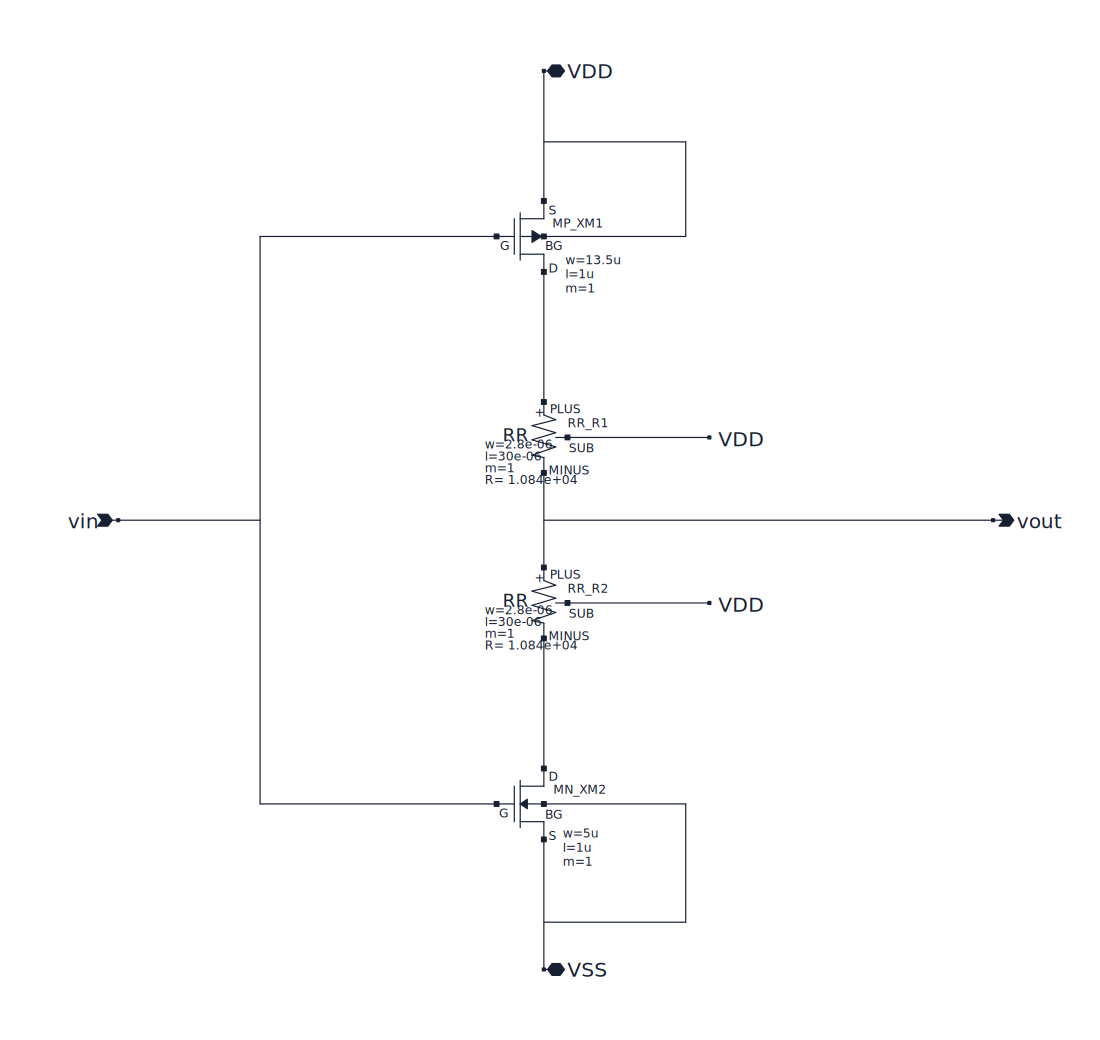

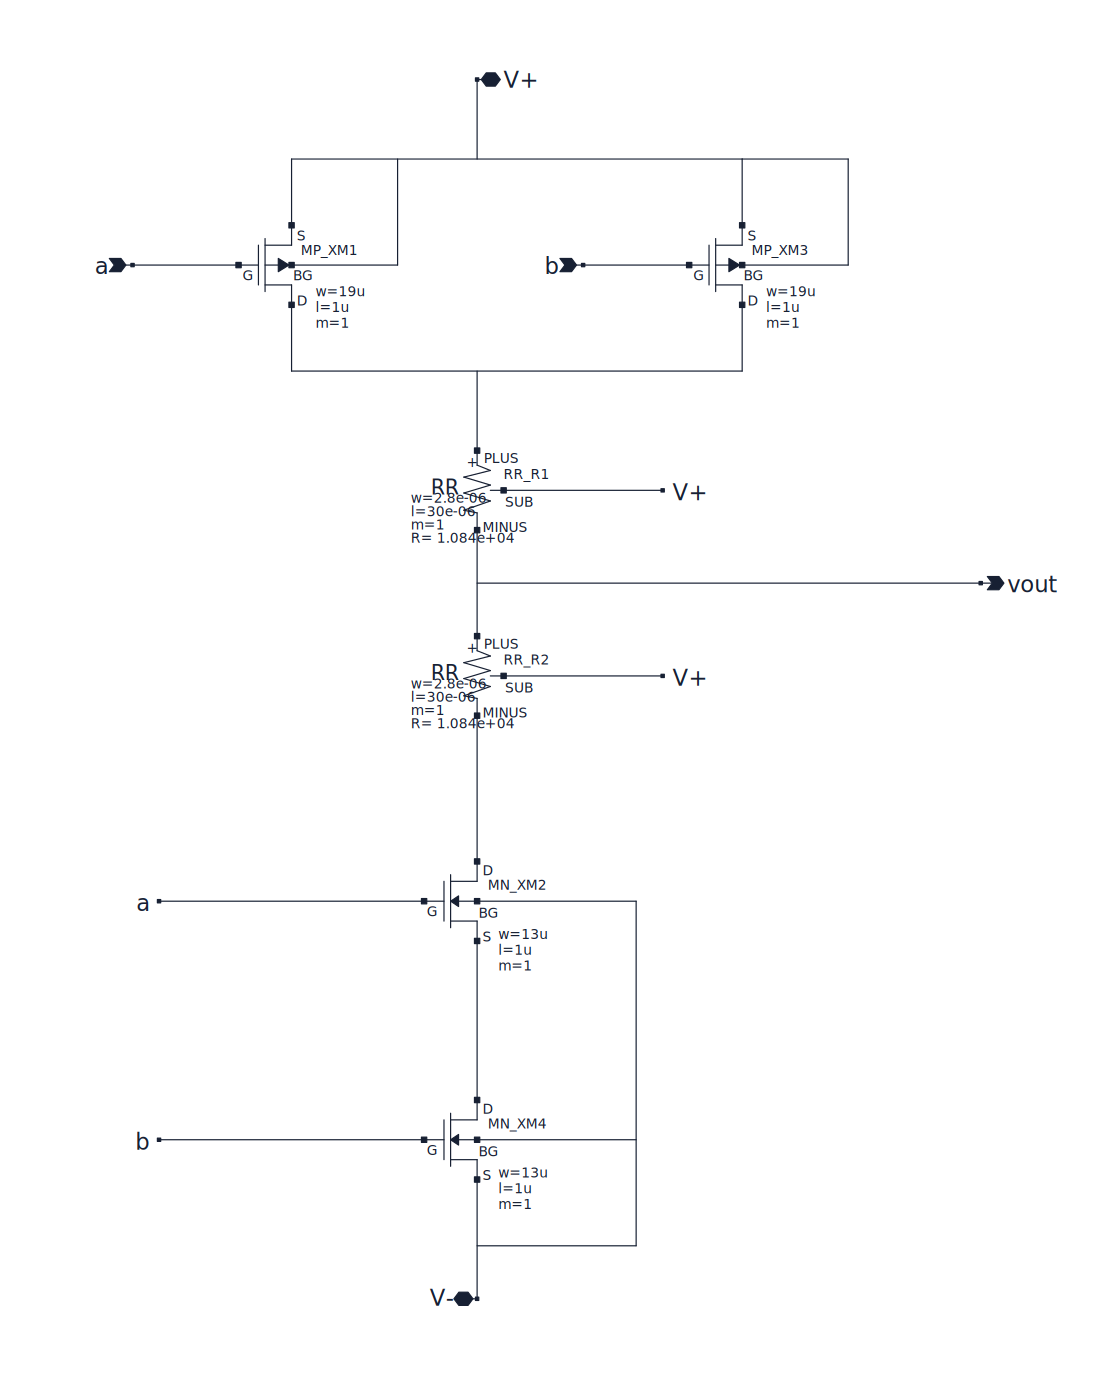

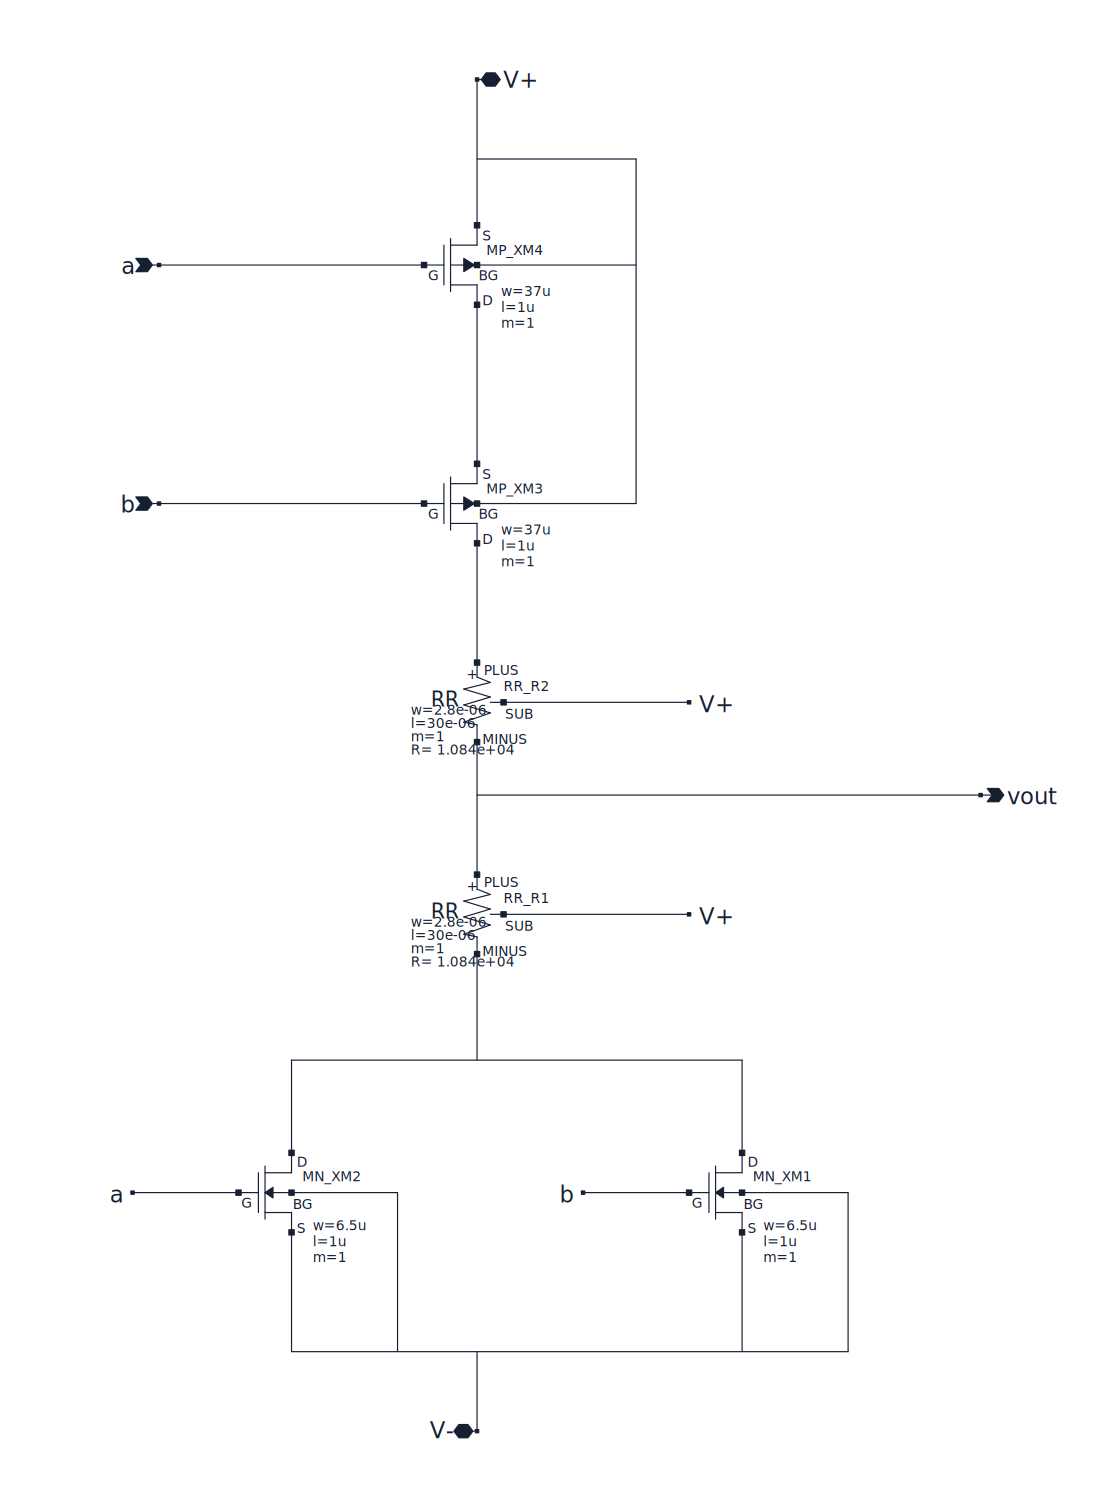

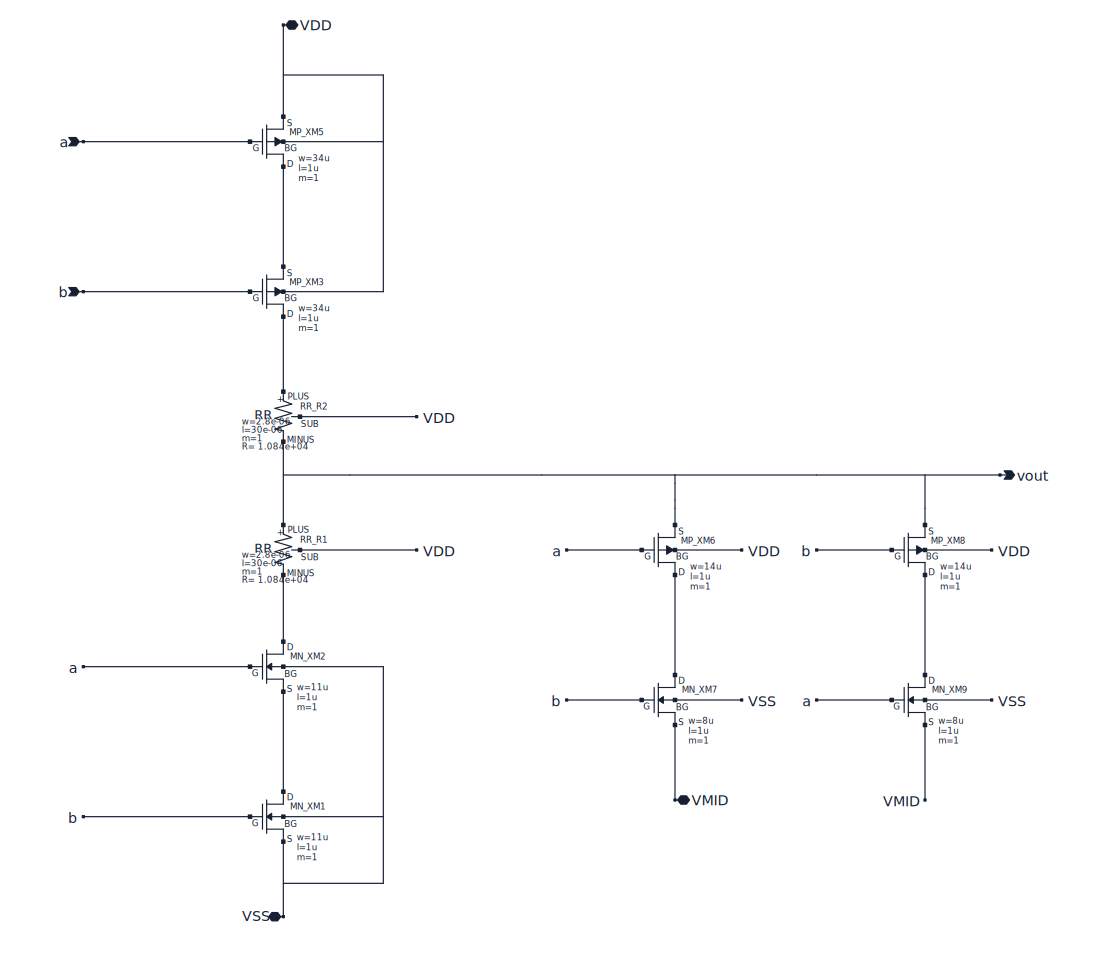

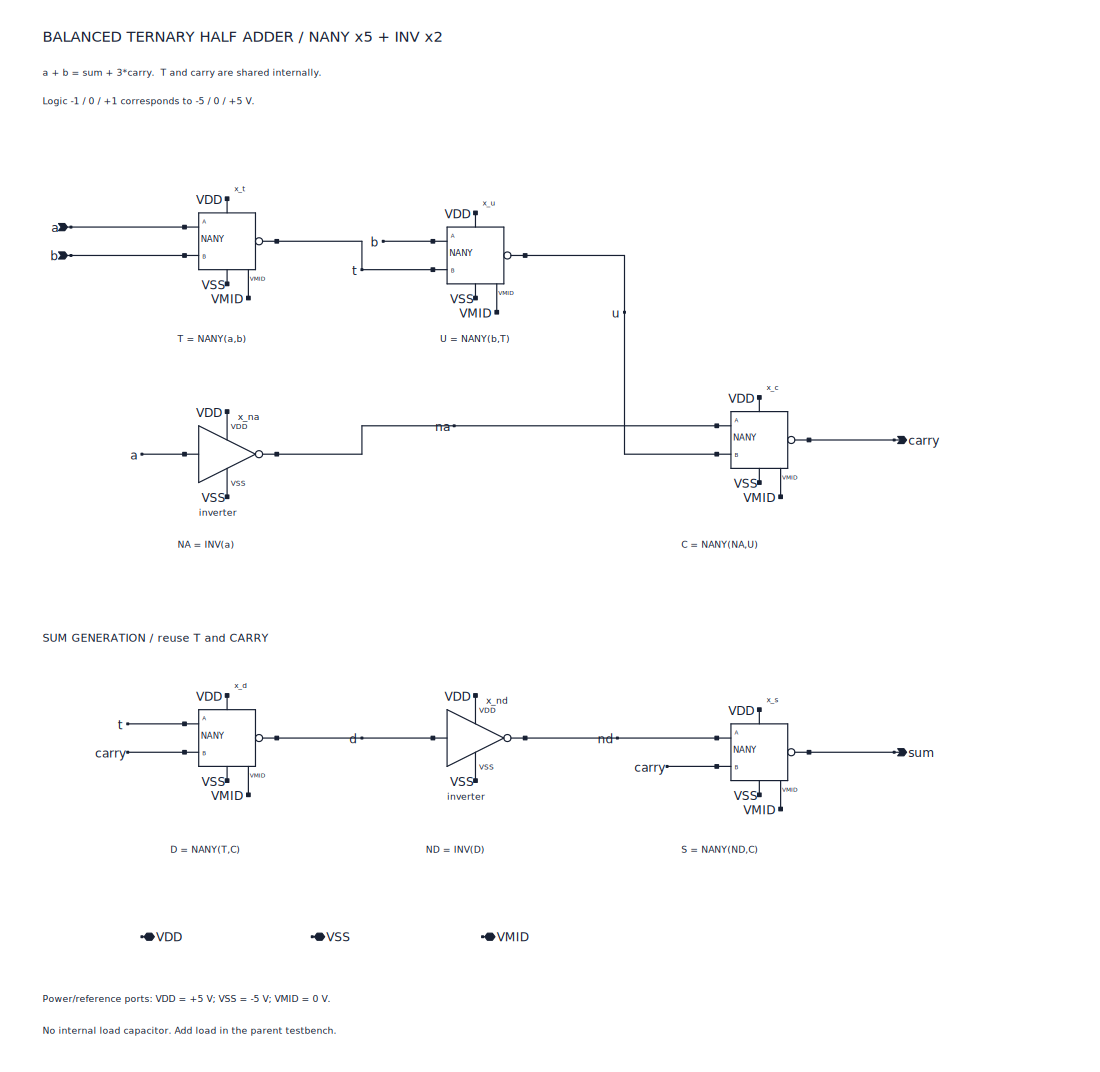

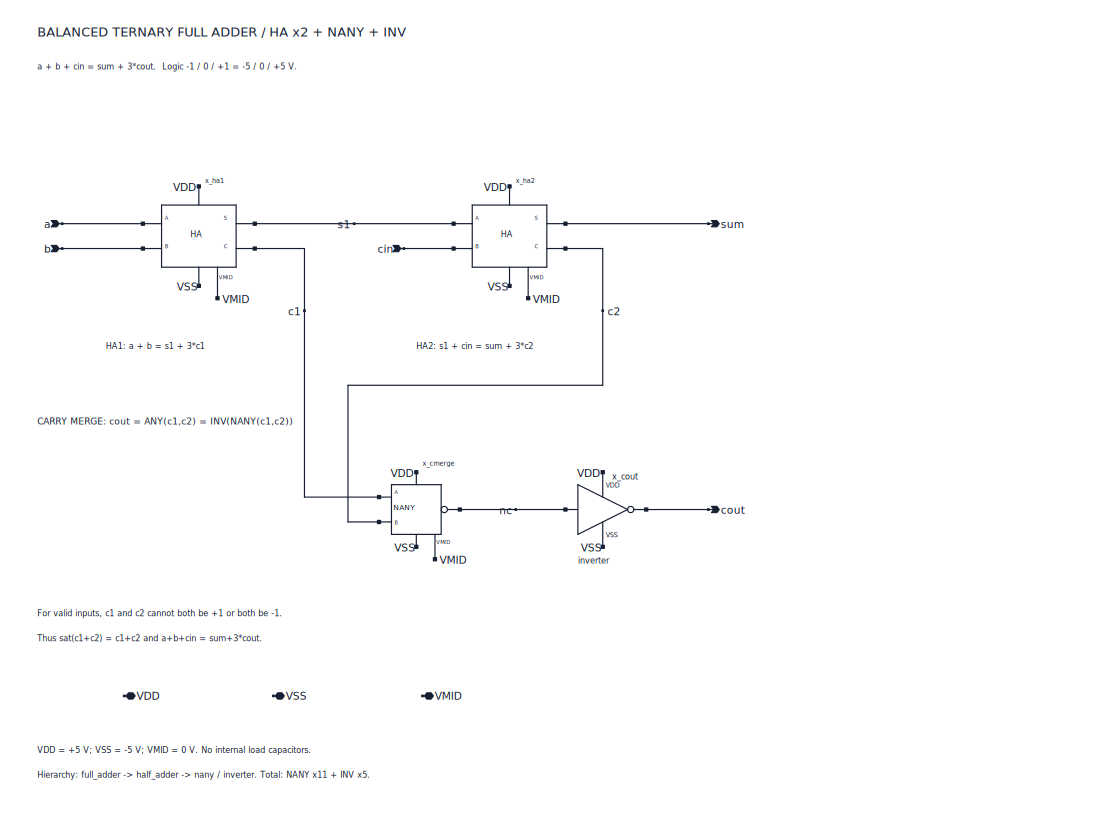

Running: nany-dc


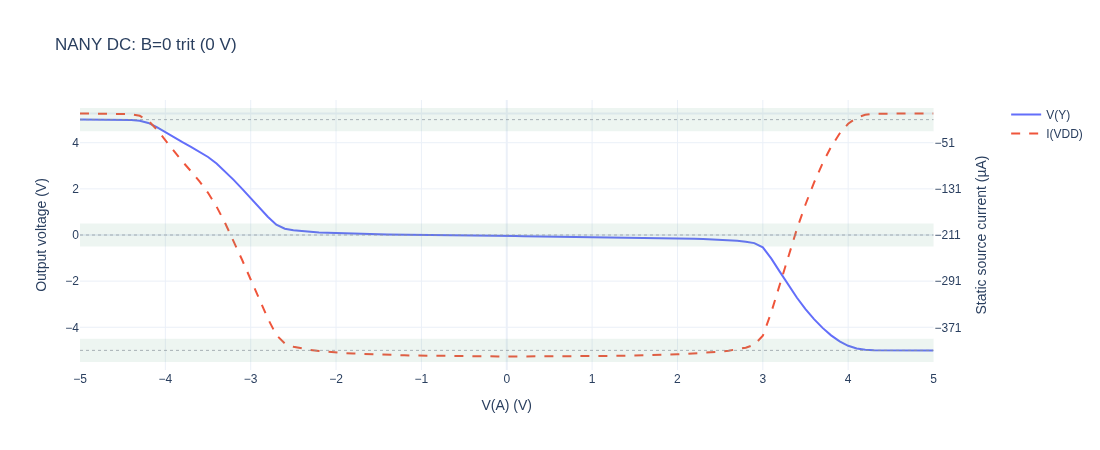

In [5]:
gates = flow.loads("""module gates(input trit a,b,output trit inva,nandab,norab,nanyab);
 assign inva=~a; assign nandab=~(a&b); assign norab=~(a|b); assign nanyab=nany(a,b);
 endmodule""")
t = gates.truth_table()
assert np.array_equal(t["inva"], -t["a"])
assert np.array_equal(t["nandab"], -np.minimum(t["a"], t["b"]))
assert np.array_equal(t["norab"], -np.maximum(t["a"], t["b"]))
assert np.array_equal(t["nanyab"], -np.clip(t["a"]+t["b"],-1,1))
display(truth_table_html(gates.design))
for name in ["INV","NAND","NOR","NANY"]:
    body = subcircuits((CELLS_DIR/f"out/{name}/{name}.spice").read_text())[name.lower()]["body"]
    assert ("VMID" in body.upper()) == (name == "NANY"), name
display(HTML(schematic_gallery(ROOT/"notebook/assets/schematics")))
cell_spice = (CELLS_DIR/"out/NANY/NANY.ext.spice").read_text()
DC_FIXED_B, DC_STEP_V = 0, .1
curve = cache.run("nany-dc", {"fixed_B": DC_FIXED_B, "step_v": DC_STEP_V}, lambda:
    dc_transfer(cell_spice, "NANY", ["A","B"], ["Y"], "A",
                fixed_trits={"B":DC_FIXED_B}, step_v=DC_STEP_V))
show(transfer_figure(curve, "A", ["Y"],
                     title=f"NANY DC: B={DC_FIXED_B} trit ({TRIT_VOLTS[DC_FIXED_B]:g} V)"))


The primitive crops retain instance W/L properties and omit obsolete free-text
sizing sidebars in the source drawings. Light/dark variants have opaque backing;
expand the provenance control to compare them. NANY's clamp uses VMID; the
other displayed primitive bodies do not, as checked against their SPICE above.

## 2. Size and characterize a cell

The table reads the published characterization, verifies its source/model
hashes, and checks its recorded pass flags. Conditions and tested loads are
shown from that data. Input capacitance is a biased AC driving-point measure,
including Miller response. Fanout method/scope are shown verbatim from the
record: these nominal tests do not establish PVT or arbitrary path timing.


In [6]:
characters = {cell: json.loads((CELLS_DIR/f"out/{cell}/{cell}.char.json").read_text())
              for cell in ["INV","NAND","NOR","NANY","BUF"]}
rows = [["Cell", "Max DC error (mV)", "Max static rail |I| (µA)", "Input C (fF)", "Suggested fanout"]]
for cell, char in characters.items():
    assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.ext.spice").read_bytes()).hexdigest() == char["source_sha256"]
    assert all(hashlib.sha256((PDK_ROOT/"libs.tech/spice/models"/name).read_bytes()).hexdigest() == value
               for name,value in char["model_sha256"].items()), cell
    assert char["passed"] and all(row["passed"] for row in char["dc"])
    assert len({tuple(row["input_trits"]) for row in char["dc"]}) == 3**len(char["inputs"])
    assert all(result["passed"] for result in char["transient"])
    rows.append([cell, 1e3*max(abs(v) for row in char["dc"] for v in row["error_v"].values()),
                 max(abs(i) for row in char["dc"] for i in row["rail_current_a"].values())*1e6,
                 char["input_capacitance"]["max_f"]*1e15, char["fanout"]["suggested_max"]])
table(rows)
table([["Cell", "Recorded conditions", "Tested loads (fF)", "Fanout evidence"]]+
      [[cell, char["conditions"], [r["load_f"]*1e15 for r in char["transient"]], char["fanout"]]
       for cell,char in characters.items()])
fanout_rows = [["Cell", "Measured receiver counts", "Chain depth", "Worst chain (ns)",
                "Driver at largest tested fanout (ns)", "Max level error (mV)"]]
for cell, char in characters.items():
    cascade = char["cascade"]
    assert cascade["source_sha256"] == char["source_sha256"]
    assert cascade["passed"] and cascade["chains_passed"] and all(c["passed"] for c in cascade["cases"])
    largest = max(cascade["fanouts_tested"])
    chain_times = [t for c in cascade["cases"] if c["mode"] == "chain"
                   for t in c["max_settling_s"].values() if t is not None]
    loaded_times = [c["max_settling_s"]["y0"] for c in cascade["cases"]
                    if c["mode"] == "fanout" and c["fanout"] == largest]
    fanout_rows.append([cell, cascade["fanouts_tested"], cascade["chain_depth"],
                       max(chain_times)*1e9, max(loaded_times)*1e9,
                       max(c["max_error_v"] for c in cascade["cases"])*1e3])
table(fanout_rows)


Cell,Max DC error (mV),Max static rail |I| (µA),Input C (fF),Suggested fanout
INV,39.54206875238568,407.1662464871755,114.42603602817093,8
NAND,102.6605579347912,435.3772831223841,206.13240229730908,8
NOR,158.9965248616333,434.20678346046617,277.9882339437619,8
NANY,44.599836209768746,421.36110385251857,394.0605904524237,8
BUF,35.23708763780001,814.3015572524799,114.4260518125108,8


Cell,Recorded conditions,Tested loads (fF),Fanout evidence
INV,"{'temperature_c': 27, 'supplies_v': {'VDD': 5, 'VMID': 0, 'VSS': -5}, 'band_v': 0.5, 'edge_s': 1e-09, 'hold_s': 2e-07, 'step_s': 5e-10}","[10.0, 100.0, 1000.0]","{'suggested_max': 8, 'tested_counts': [1, 2, 4, 8], 'capacitance_estimate_max': 4, 'method': 'measured self-loading; every receiver pin and other-input trit bias; five-stage chains', 'scope': 'nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT', 'chain_depth': 5}"
NAND,"{'temperature_c': 27, 'supplies_v': {'VDD': 5, 'VMID': 0, 'VSS': -5}, 'band_v': 0.5, 'edge_s': 1e-09, 'hold_s': 2e-07, 'step_s': 5e-10}","[10.0, 100.0, 1000.0]","{'suggested_max': 8, 'tested_counts': [1, 2, 4, 8], 'capacitance_estimate_max': 4, 'method': 'measured self-loading; every receiver pin and other-input trit bias; five-stage chains', 'scope': 'nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT', 'chain_depth': 5}"
NOR,"{'temperature_c': 27, 'supplies_v': {'VDD': 5, 'VMID': 0, 'VSS': -5}, 'band_v': 0.5, 'edge_s': 1e-09, 'hold_s': 2e-07, 'step_s': 5e-10}","[10.0, 100.0, 1000.0]","{'suggested_max': 8, 'tested_counts': [1, 2, 4, 8], 'capacitance_estimate_max': 3, 'method': 'measured self-loading; every receiver pin and other-input trit bias; five-stage chains', 'scope': 'nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT', 'chain_depth': 5}"
NANY,"{'temperature_c': 27, 'supplies_v': {'VDD': 5, 'VMID': 0, 'VSS': -5}, 'band_v': 0.5, 'edge_s': 1e-09, 'hold_s': 2e-07, 'step_s': 5e-10}","[10.0, 100.0, 1000.0]","{'suggested_max': 8, 'tested_counts': [1, 2, 4, 8], 'capacitance_estimate_max': 2, 'method': 'measured self-loading; every receiver pin and other-input trit bias; five-stage chains', 'scope': 'nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT', 'chain_depth': 5}"
BUF,"{'temperature_c': 27, 'supplies_v': {'VDD': 5, 'VMID': 0, 'VSS': -5}, 'band_v': 0.5, 'edge_s': 1e-09, 'hold_s': 2e-07, 'step_s': 5e-10}","[10.0, 100.0, 1000.0]","{'suggested_max': 8, 'tested_counts': [1, 2, 4, 8], 'capacitance_estimate_max': 4, 'method': 'measured self-loading; every receiver pin and other-input trit bias; five-stage chains', 'scope': 'nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT', 'chain_depth': 5}"


Cell,Measured receiver counts,Chain depth,Worst chain (ns),Driver at largest tested fanout (ns),Max level error (mV)
INV,"[1, 2, 4, 8]",5,15.105431661664634,36.02954434464455,39.536603090298094
NAND,"[1, 2, 4, 8]",5,35.50319918829773,65.32593581065731,104.28280381892439
NOR,"[1, 2, 4, 8]",5,64.53281577460814,94.49941136712313,158.9378496682913
NANY,"[1, 2, 4, 8]",5,70.26272969980994,144.887426995334,106.490962298726
BUF,"[1, 2, 4, 8]",5,27.053486750774177,37.87398902465424,35.655593405361394


Each receiver is a transistor-level load. The largest tested count is a measured
nominal bound, not an extrapolation to larger fanout or PVT. The chain checks
every intermediate output. Isolated-cell load sweeps and self-loading chains
answer different questions; their conditions are displayed separately above.

**SIM publication slot — W/L sweep:** `cells/out/sizing/` supplies cached
transfer/error/current data. When available, the code below reads SIM's public
`load_grid(cell)` and uses `sizing_figure(result)` to mark the adopted dimensions.
Missing or stale grids leave an explicit TODO. Full characterization is not
rerun by default. To compute new sparse device overrides, use
`sweep_dimensions(cell, candidates, *, sweep_pin="A", fixed_trits=None,
start_v=-5., stop_v=5., step_v=.1, temperature_c=27., pdk=None,
workdir=None, timeout=120.)`; W/L values are µm, not SPICE metre suffixes.


Cell,Candidates,PASS,Adopted dimensions (µm),Conditions
INV,90,76,"{'MP': {'w_um': 13.5, 'l_um': 1.0}, 'MN': {'w_um': 5.0, 'l_um': 1.0}, 'RP': {'w_um': 2.8, 'l_um': 30.0}, 'RN': {'w_um': 2.8, 'l_um': 30.0}}","{'supplies_v': {'VDD': 5.0, 'VMID': 0.0, 'VSS': -5.0}, 'temperature_c': 27.0, 'band_v': 0.5, 'sweep_pin': 'A', 'fixed_trits': {}, 'start_v': -5.0, 'stop_v': 5.0, 'step_v': 0.1}"


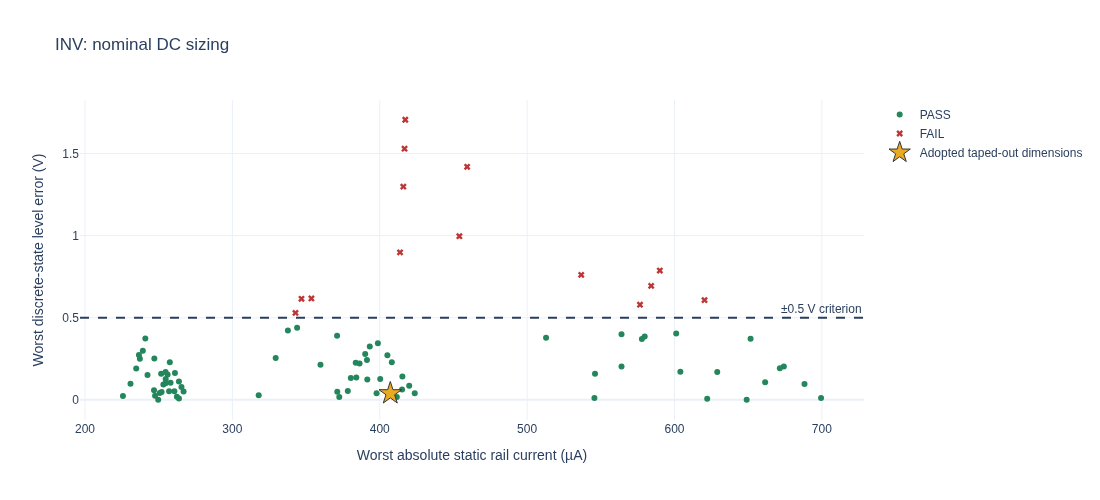

Selected candidate,0
Dimensions (µm),"{'MP': {'w_um': 13.5, 'l_um': 1.0}, 'MN': {'w_um': 5.0, 'l_um': 1.0}, 'RP': {'w_um': 2.8, 'l_um': 30.0}, 'RN': {'w_um': 2.8, 'l_um': 30.0}}"
PASS / solver error,"[True, None]"


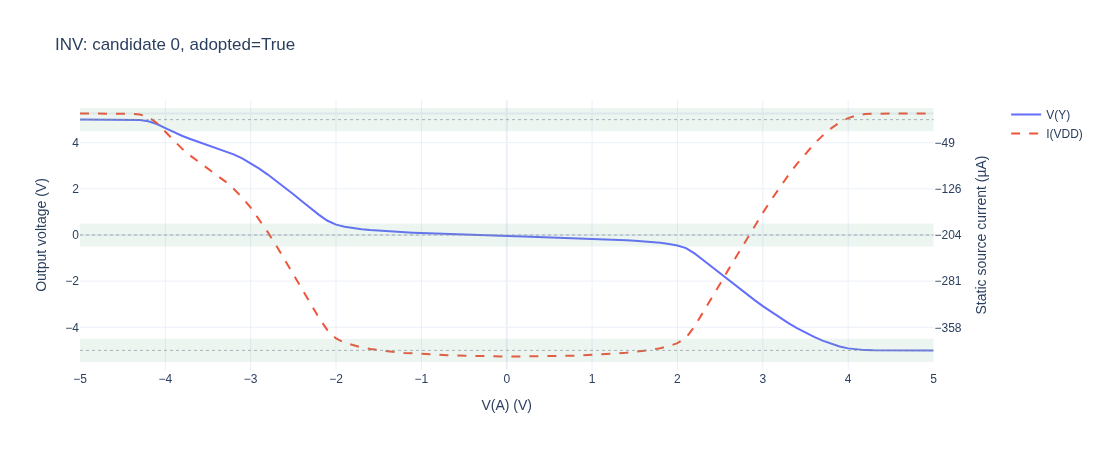

Cell,Candidates,PASS,Adopted dimensions (µm),Conditions
NANY,18,17,"{'P1': {'w_um': 34.0, 'l_um': 1.0}, 'P2': {'w_um': 34.0, 'l_um': 1.0}, 'N1': {'w_um': 11.0, 'l_um': 1.0}, 'N2': {'w_um': 11.0, 'l_um': 1.0}, 'CP1': {'w_um': 14.0, 'l_um': 1.0}, 'CN1': {'w_um': 8.0, 'l_um': 1.0}, 'CP2': {'w_um': 14.0, 'l_um': 1.0}, 'CN2': {'w_um': 8.0, 'l_um': 1.0}, 'RP': {'w_um': 2.8, 'l_um': 30.0}, 'RN': {'w_um': 2.8, 'l_um': 30.0}}","{'supplies_v': {'VDD': 5.0, 'VMID': 0.0, 'VSS': -5.0}, 'temperature_c': 27.0, 'band_v': 0.5, 'sweep_pin': 'A', 'fixed_trits': {'B': 0}, 'start_v': -5.0, 'stop_v': 5.0, 'step_v': 0.1}"


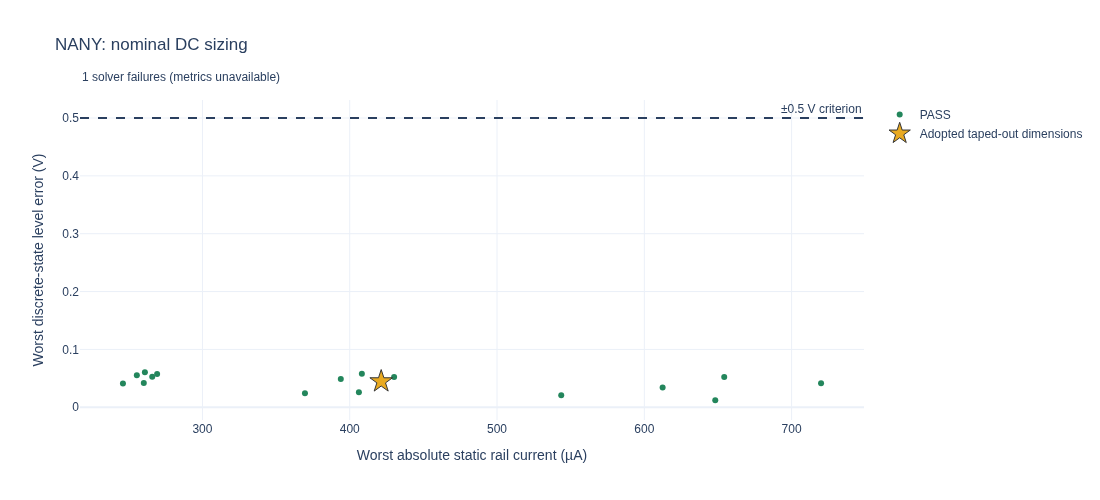

Selected candidate,0
Dimensions (µm),"{'P1': {'w_um': 34.0, 'l_um': 1.0}, 'P2': {'w_um': 34.0, 'l_um': 1.0}, 'N1': {'w_um': 11.0, 'l_um': 1.0}, 'N2': {'w_um': 11.0, 'l_um': 1.0}, 'CP1': {'w_um': 14.0, 'l_um': 1.0}, 'CN1': {'w_um': 8.0, 'l_um': 1.0}, 'CP2': {'w_um': 14.0, 'l_um': 1.0}, 'CN2': {'w_um': 8.0, 'l_um': 1.0}, 'RP': {'w_um': 2.8, 'l_um': 30.0}, 'RN': {'w_um': 2.8, 'l_um': 30.0}}"
PASS / solver error,"[True, None]"


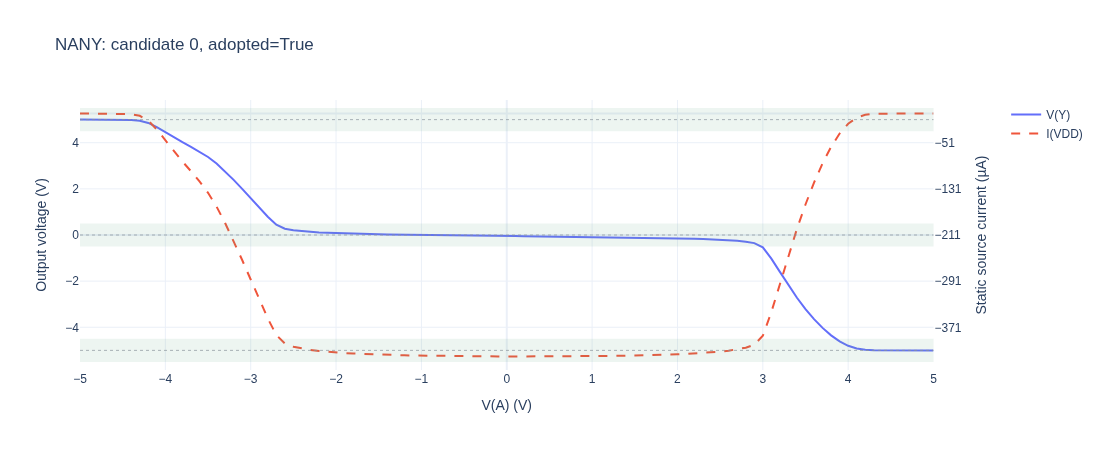

In [7]:
from tritflow.sim.sizing import load_grid, sweep_dimensions
from tritflow.viz.scaling import sizing_figure
SIZING_INDEX = {"INV": None, "NANY": None}  # None selects adopted; set a candidate index to inspect it
for cell in ["INV", "NANY"]:
    if not (CELLS_DIR/f"out/sizing/{cell}.grid.json").is_file():
        print(f"TODO SIM: publish cells/out/sizing/{cell}.grid.json (W/L sweep)")
        continue
    try:
        grid = load_grid(cell)
    except RuntimeError as error:
        print(f"TODO SIM: refresh {cell} sizing grid: {error}")
        continue
    adopted = grid["rows"][grid["adopted_index"]]
    table([["Cell", "Candidates", "PASS", "Adopted dimensions (µm)", "Conditions"],
           [cell, len(grid["rows"]), sum(r["passed"] for r in grid["rows"]),
            adopted["dimensions"], grid["conditions"]]])
    show(sizing_figure(grid))
    index = grid["adopted_index"] if SIZING_INDEX[cell] is None else SIZING_INDEX[cell]
    candidate = grid["rows"][index]
    table([["Selected candidate",index], ["Dimensions (µm)",candidate["dimensions"]],
           ["PASS / solver error",[candidate["passed"],candidate["error"]]]])
    if candidate["transfer"] is not None:
        show(transfer_figure(candidate["transfer"],grid["conditions"]["sweep_pin"],["Y"],
                             title=f"{cell}: candidate {index}, adopted={candidate['is_adopted']}"))


## 3. Read the standard-cell views

Every cell supplies GDS, source SPICE, extracted SPICE, a physical abstract and
characterization. Rails run VDD / cell body / VMID / VSS. Read actual dimensions
and obstructions from the template/abstract; compact cells may use internal M2
and V1 if declared as routing obstacles. R0 and left/right reflection preserve
rail polarity. Cell-local DRC/LVS and abutment qualification are distinct from
top-level routed checks. The table verifies the published report's artifact
hashes before showing its flags; chapter 0 checks the routed design. TIE drive
remains a load-dependent property.


Published library generation: 2026-10-18T08:40:04.261111+00:00


Cell,Width × common height (µm),Area (µm²),Free full-height M2 tracks
INV,"[108.0, 132.0]",14256.0,13
NAND,"[144.0, 132.0]",19008.0,6
NOR,"[144.0, 132.0]",19008.0,6
NANY,"[168.0, 132.0]",22176.0,3
BUF,"[216.0, 132.0]",28512.0,25
TIEP,"[72.0, 132.0]",9504.0,9
TIEZ,"[72.0, 132.0]",9504.0,8
TIEN,"[72.0, 132.0]",9504.0,8
FILL,"[24.0, 132.0]",3168.0,2


Height (µm),132.0
Grid (µm),6.0
NANY width (µm),168.0
Rails,"{'VDD': [124.0, 132.0], 'VMID': [6.0, 10.0], 'VSS': [0.0, 4.0]}"
Pin names,"['A', 'B', 'Y', 'VDD', 'VMID', 'VSS']"
Obstruction layers,"['M1', 'M2', 'V1']"


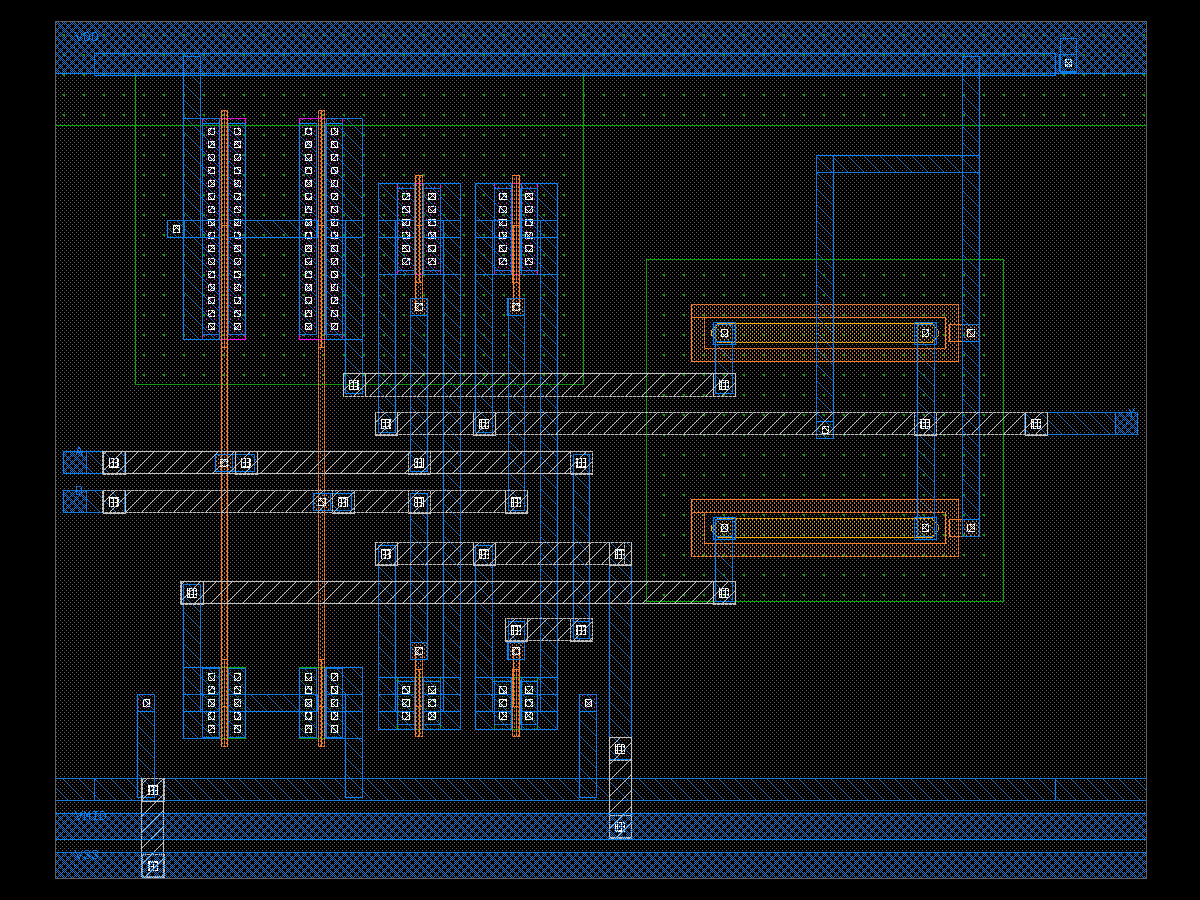

Cell,Recorded DRC clean,Recorded LVS qualification,LVS method
INV,True,True,strict device/port comparison
NAND,True,True,strict device/port comparison
NOR,True,True,strict device/port comparison
NANY,True,True,strict device/port comparison
BUF,True,True,strict device/port comparison
TIEP,True,True,strict device/port comparison
TIEZ,True,True,strict device/port comparison
TIEN,True,True,strict device/port comparison
FILL,True,True,empty-device extraction + strict three-rail RR probe fixture


FILL qualification: PDK purges device-free FILL; standalone comparison has no circuits. No device mismatch is waived.
Recorded qualification scope: nominal device/connectivity extraction, no interconnect RC


In [8]:
template = json.loads((CELLS_DIR/"template.json").read_text())
generation = json.loads((CELLS_DIR/"out/generation.json").read_text())
abstracts = {item["name"]:json.loads((CELLS_DIR/"out"/item["abstract"]).read_text())
             for item in json.loads((CELLS_DIR/"out/library.json").read_text())}
assert {a["height"] for a in abstracts.values()} == {template["height"]}
assert generation["height_um"] == template["height"]
print("Published library generation:", generation["id"])
table([["Cell", "Width × common height (µm)", "Area (µm²)", "Free full-height M2 tracks"]]+
      [[name, [a["width"],a["height"]], a["width"]*a["height"], a["free_M2_tracks"]["count"]]
       for name,a in abstracts.items()])
abstract = json.loads((CELLS_DIR/"out/NANY/NANY.abstract.json").read_text())
table([["Height (µm)", template["height"]], ["Grid (µm)", template["grid"]],
       ["NANY width (µm)", abstract["width"]], ["Rails", template["rails"]],
       ["Pin names", list(abstract["pins"])], ["Obstruction layers", list(abstract["obstructions"])]])
image = CELLS_DIR/"out/NANY/NANY.png"
if image.is_file():
    display(Image(filename=str(image), width=700))
qualification = CELLS_DIR/"out/verify_report.json"
if qualification.is_file():
    report = json.loads(qualification.read_text())
    assert report["passed"]
    for cell, artifacts in report["artifact_sha256"].items():
        for suffix, expected_hash in artifacts.items():
            assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.{suffix}").read_bytes()).hexdigest() == expected_hash
    table([["Cell", "Recorded DRC clean", "Recorded LVS qualification", "LVS method"]]+[
        [name, result["drc"]["passed"], result["lvs"]["passed"],
         result["lvs"].get("method","strict device/port comparison")]
        for name,result in report["cells"].items()])
    if "FILL" in report["cells"]:
        print("FILL qualification:", report["cells"]["FILL"]["lvs"]["explanation"])
    print("Recorded qualification scope:", report["scope"])
else:
    print("TODO CELLS: publish the cell qualification report; no cell-clean claim is made here")


## 4. Describe arithmetic in TritVerilog

The reference half adder shares intermediates. Two such blocks and carry
combination produce the full adder. Gate counts are computed below and asserted
against the authored hierarchy. Its invariant is a+b+cin = sum+3·cout. Generate loops
replicate that slice; bit i has integer weight 3ⁱ. Only parameters/indices use
integer arithmetic in HDL; signal arithmetic is implemented with gates.


In [9]:
ha = flow.load(ROOT/"examples/half_add.tv", "half_add")
fa = flow.load(ROOT/"examples/full_add.tv", "full_add")
display(truth_table_html(ha.design))
display(truth_table_html(fa.design))
fa_table = fa.truth_table()
ha_table = ha.truth_table()
assert np.array_equal(ha_table["a"]+ha_table["b"], ha_table["sum"]+3*ha_table["carry"])
assert np.array_equal(fa_table["a"]+fa_table["b"]+fa_table["cin"],
                      fa_table["sum"]+3*fa_table["cout"])
ha_counts, fa_counts = ha.synthesize().report()["cells"], fa.synthesize().report()["cells"]
schematic_sources = json.loads((ROOT/"notebook/assets/schematics/manifest.json").read_text())["schematics"]
ha_symbols = schematic_sources["half_adder"]["instances_by_symbol"]
fa_symbols = schematic_sources["full_adder"]["instances_by_symbol"]
symbol_names = {"INV":"inverter", "NANY":"nany"}
assert ha_counts == {cell:ha_symbols[symbol] for cell,symbol in symbol_names.items()}
assert fa_counts == {cell:fa_symbols["half_adder"]*ha_counts[cell]+fa_symbols[symbol]
                     for cell,symbol in symbol_names.items()}
table([["Circuit", "Cells", "Exhaustive input states"],
       ["half_add",ha_counts,len(ha_table["sum"])], ["full_add",fa_counts,len(fa_table["sum"])]])
print((ROOT/"examples/adder.tv").read_text())


Vector,ainput,binput,sumoutput,carryoutput
1,-1,-1,+1,-1
2,-1,0,-1,0
3,-1,+1,0,0
4,0,-1,-1,0
5,0,0,0,0
6,0,+1,+1,0
7,+1,-1,0,0
8,+1,0,+1,0
9,+1,+1,-1,+1


Vector,ainput,binput,cininput,sumoutput,coutoutput
1,-1,-1,-1,0,-1
2,-1,-1,0,+1,-1
3,-1,-1,+1,-1,0
4,-1,0,-1,+1,-1
5,-1,0,0,-1,0
6,-1,0,+1,0,0
7,-1,+1,-1,-1,0
8,-1,+1,0,0,0
9,-1,+1,+1,+1,0
10,0,-1,-1,+1,-1


Circuit,Cells,Exhaustive input states
half_add,"{'INV': 2, 'NANY': 5}",9
full_add,"{'INV': 5, 'NANY': 11}",27


`include "full_add.tv"
// Little-endian arithmetic: a[i] and b[i] have weight 3**i.
// A + B + cin = SUM + 3**N * cout; N must be >= 1.
module adder #(parameter N = 4)
  (input trit [N-1:0] a, b, input trit cin,
   output trit [N-1:0] sum, output trit cout);
  wire trit [N:0] c;
  assign c[0] = cin;
  genvar i;
  generate
    for (i = 0; i < N; i = i + 1) begin : digit
      full_add fa (.a(a[i]), .b(b[i]), .cin(c[i]),
                   .sum(sum[i]), .cout(c[i+1]));
    end
  endgenerate
  assign cout = c[N];
endmodule



## 5. Follow synthesis into cells

Constant folding, double-negation removal, common-expression sharing and dead
logic removal operate on the ternary DAG. Negated min/max fuse into NAND/NOR;
positive min/max use NAND/NOR followed by INV. Constants map to TIEP/TIEZ/TIEN.
Authored live primitives retain identity. BUF trees bound input-pin fanout;
separate output aliases also need physical drivers. The synthesis report shows
the equivalence mode and vector count actually used for this design.


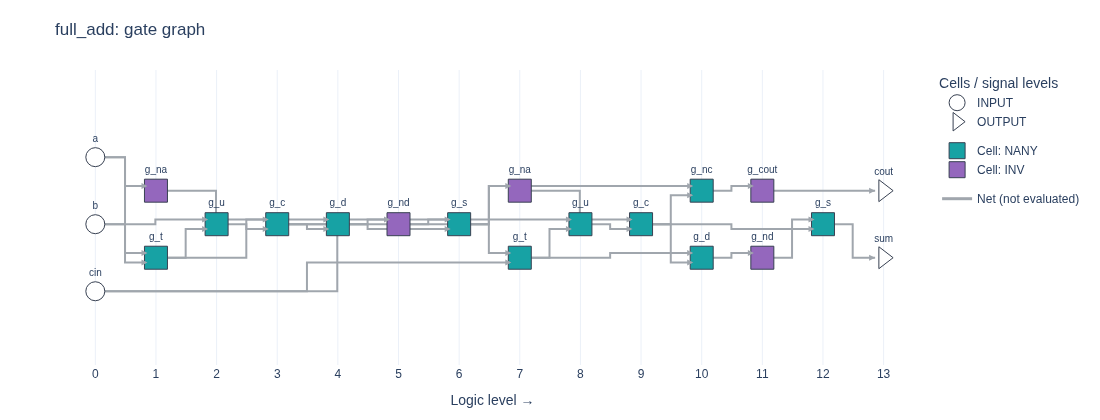

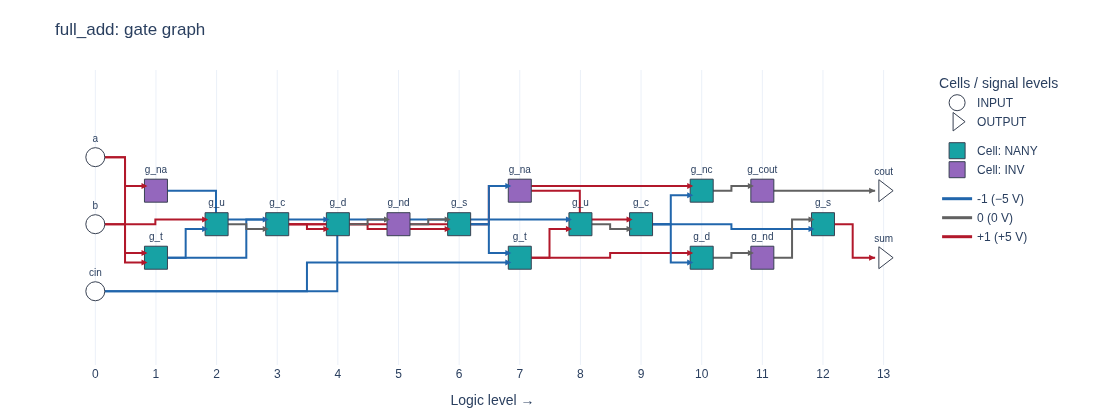

Report field,Value
top,full_add
cells,"{'INV': 5, 'NANY': 11}"
total_cells,16
logic_depth,12
hierarchy,"{'<top>': {'INV': 1, 'NANY': 1}, 'ha1': {'INV': 2, 'NANY': 5}, 'ha2': {'INV': 2, 'NANY': 5}}"
max_fanout,3
fanout_limit,4
equivalence,"{'passed': True, 'mode': 'exhaustive', 'vectors': 27, 'seed': None}"


// Generated combinational TritVerilog; trits are -1/0/+1.
module full_add(input trit a, input trit b, input trit cin, output trit sum, output trit cout);
  wire trit _n0;
  wire trit _n1;
  wire trit _n10;
  wire trit _n11;
  wire trit _n12;
  wire trit _n14;
  wire trit _n2;
  wire trit _n3;
  wire trit _n4;
  wire trit _n5;
  wire trit _n6;
  wire trit _n7;
  wire trit _n8;
  wire trit _n9;
  nany \ha1.g_t (_n0, a, b);
  inv \ha1.g_na (_n1, a);
  nany \ha1.g_u (_n2, b, _n0);
  nany \ha1.g_c (_n3, _n1, _n2);
  nany \ha1.g_d (_n4, _n0, _n3);
  inv \ha1.g_nd (_n5, _n4);
  nany \ha1.g_s (_n6, _n5, _n3);
  nany \ha2.g_t (_n7, _n6, cin);
  inv \ha2.g_na (_n8, _n6);
  nany \ha2.g_u (_n9, cin, _n7);
  nany \ha2.g_c (_n10, _n8, _n9);
  nany \ha2.g_d (_n11, _n7, _n10);
  nany g_nc(_n14, _n3, _n10);
  inv \ha2.g_nd (_n12, _n11);
  inv g_cout(cout, _n14);
  nany \ha2.g_s (sum, _n12, _n10);
endmodule



HDL expression,Computed cells
~a,{'INV': 1}
~(a&b),{'NAND': 1}
a&b,"{'INV': 1, 'NAND': 1}"
~(a|b),{'NOR': 1}
a|b,"{'INV': 1, 'NOR': 1}"
"nany(a,b)",{'NANY': 1}
1'tT,{'TIEN': 1}
1't0,{'TIEZ': 1}
1't1,{'TIEP': 1}


In [10]:
fa_net = fa.synthesize()
assert fa_net.report()["equivalence"]["passed"]
assert fa_net.report()["equivalence"]["vectors"] == len(fa_table["sum"])
show(gate_graph(fa_net))
show(color_nets(fa_net, {"a": 1, "b": 1, "cin": -1}))
table([["Report field", "Value"]]+[[k,v] for k,v in fa_net.report().items()])
from tritflow.synth import tritverilog
print(tritverilog(fa_net))
mapping_cases = [("~a",["INV"]), ("~(a&b)",["NAND"]), ("a&b",["NAND","INV"]),
                 ("~(a|b)",["NOR"]), ("a|b",["NOR","INV"]), ("nany(a,b)",["NANY"]),
                 ("1'tT",["TIEN"]), ("1't0",["TIEZ"]), ("1't1",["TIEP"])]
mapping_rows = [["HDL expression", "Computed cells"]]
for expr, expected_cells in mapping_cases:
    mapped = flow.loads(f"module mapping(input trit a,b,output trit y); assign y={expr}; endmodule").synthesize()
    assert sorted(inst.cell for inst in mapped.instances) == sorted(expected_cells)
    mapping_rows.append([expr, mapped.report()["cells"]])
table(mapping_rows)


## 6. Place, route and inspect GDS

The physical flow starts from signal-order placement, seeks shorter connections
with seeded annealing, and routes with A* and rip-up/retry on a two-layer grid. M1 routes
use channels; M2 crosses cells while respecting declared obstructions. Three
supplies connect row rails to trunks. Independent checks inspect drawn metal
islands, widths/spaces and via enclosures before the official PDK deck runs.
Top-level device LVS compares the exported GDS to mapped-cell connectivity.


Metric,Two-trit adder
die_size_um,"[1254.0, 1206.0]"
die_area_um2,1512324.0
wirelength_um,"{'M1': 16074.0, 'M2': 17246.0}"
via_count,251
power_via_count,408
utilization,0.4168630531552763
instance_count,32
row_count,6
net_count,37
spans_per_row,2


Requested rows (None = automatic),None
Annealing steps,600
Actual physical rows,6
Utilization,0.4168630531552763


Placement snapshots: 26
Routing attempts: [{'channel_tracks': 4, 'bypass_tracks_per_side': 0, 'failed_net': '_n17', 'reason': 'Routing failed for nets _n17: no legal maze path. Congested connection region: x=825..843 µm, y=586..778 µm. Nearby occupied nets: _n15, _n2, _n23, _n25, _n4, sum[1]. Try more rows (rows=...) or channel tracks (channel_tracks=...); check cell pin-access obstructions.', 'ripped_up': [{'pass': 0, 'failed_net': 'sum[1]', 'routed_nets': 17}, {'pass': 1, 'failed_net': '_n17', 'routed_nets': 18}, {'pass': 2, 'failed_net': 'a[1]', 'routed_nets': 24}, {'pass': 3, 'failed_net': '_n25', 'routed_nets': 19}, {'pass': 4, 'failed_net': '_n17', 'routed_nets': 26}, {'pass': 5, 'failed_net': '_n0', 'routed_nets': 23}, {'pass': 6, 'failed_net': 'cin', 'routed_nets': 19}, {'pass': 7, 'failed_net': '_n17', 'routed_nets': 11}], 'success': False}, {'channel_tracks': 6, 'bypass_tracks_per_side': 1, 'failed_net': '_n23', 'reason': 'Routing failed for nets _n23: no legal maze path. Con

Check,Clean
connectivity,True
routing_drc,True
pdk_drc,True


Initial / final cell-terminal HPWL (µm),"[31059.0, 16933.5]"


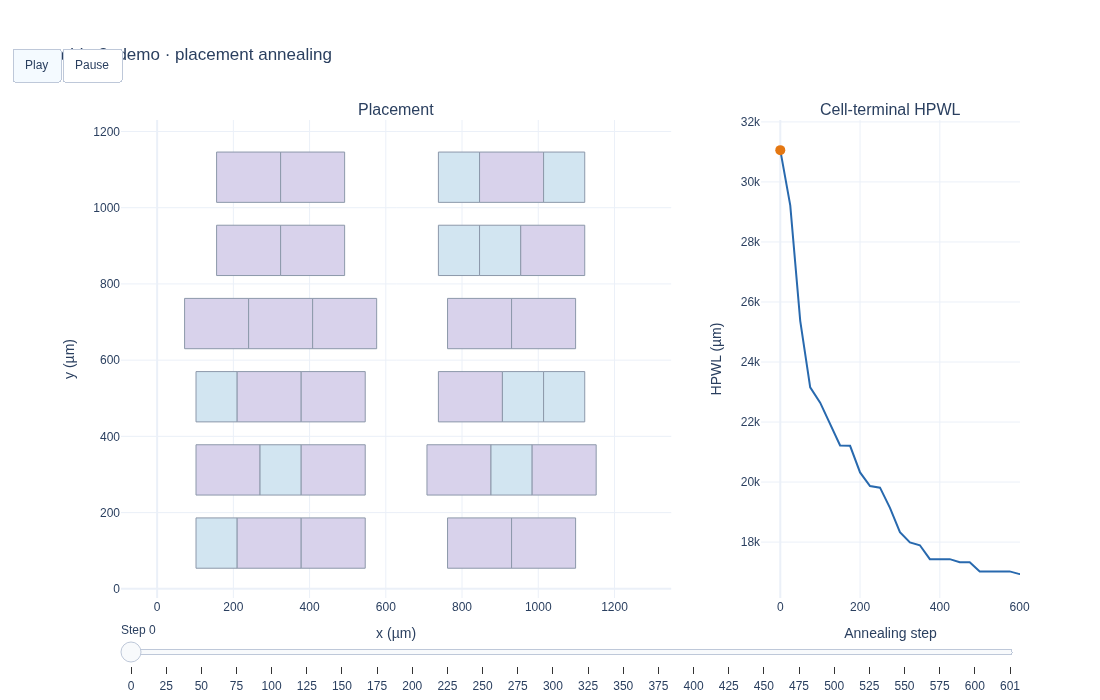

In [11]:
table([["Metric", "Two-trit adder"]]+[[k,v] for k,v in lay.stats.items()])
table([["Requested rows (None = automatic)",PNR_ROWS], ["Annealing steps",PNR_ANNEAL_STEPS],
       ["Actual physical rows",len(lay.data["rows"])], ["Utilization",lay.stats["utilization"]]])
print("Placement snapshots:", len(lay.data["history"]))
print("Routing attempts:", lay.data["routing_attempts"])
assert all(check["clean"] for check in lay.data["checks"].values())
assert lay.stats["routed_nets"] == len(net.nets())
assert {p["orient"] for p in lay.data["placements"]} <= {"R0","MY"}
table([["Check", "Clean"]]+[[name,check["clean"]] for name,check in lay.data["checks"].items()])
table([["Initial / final cell-terminal HPWL (µm)",
        [lay.data["history"][i]["hpwl"] for i in (0,-1)]]])
show(placement_animation(lay.data))
if EXTENDED:
    show(routing_progress(lay.data))
RUN_FLOORPLAN_EXPERIMENT = False  # opt in after changing the controls below
EXPERIMENT_ROWS, EXPERIMENT_ANNEAL_STEPS, EXPERIMENT_SEED = None, 2400, 7
if RUN_FLOORPLAN_EXPERIMENT:
    folder = BUILD/"floorplan_experiment"
    def route_experiment():
        routed = net.place_and_route(output_dir=folder, rows=EXPERIMENT_ROWS,
                   anneal_steps=EXPERIMENT_ANNEAL_STEPS, seed=EXPERIMENT_SEED)
        drc, lvs = routed.drc(), routed.lvs()
        assert drc["clean"] and lvs["matched"]
        return {"stats":routed.stats, "drc":drc, "lvs":lvs}
    trial = cache.run("floorplan-experiment", {"net":net.to_json(),"rows":EXPERIMENT_ROWS,
                     "steps":EXPERIMENT_ANNEAL_STEPS,"seed":EXPERIMENT_SEED}, route_experiment,
                     artifacts=[folder/f"{net.top}.gds",folder/f"{net.top}.pnr.json"])
    assert trial["drc"]["clean"] and trial["lvs"]["matched"]
    table([["Measured floorplan experiment",trial["stats"]]])
    show(placement_animation(flow.load_layout(net,folder).data))


The placement animation uses recorded snapshots and cell-terminal HPWL.
With extended experiments enabled, routing progress replays the successful
recorded pass. Neither animation substitutes for the geometry checks.
`rows=None` searches row counts and independently fed power spans for a compact,
near-square floorplan; the dimensions/aspect/utilization shown are measured.
A positive `rows` fixes the physical row count. `anneal_steps=0` retains initial
placement; more steps spend effort on swaps/moves/reflections. Change the
opt-in controls above to compare geometry and HPWL. Row/feed current constraints
remain active in every saved placement. More steps do not guarantee a better
route, and explicit row counts can reduce utilization.

## 7. Measure settled levels and wiring effects

Level pass means the sampled output lies in the configured band around its
ideal trit voltage. Overall sequence pass also requires a finite settling time.
Settling is the final entry into that band and remaining inside through the
segment end under sampled-waveform linear interpolation. The SIM API measures
from ramp **start**, including the configured input ramp. Finite timestep limits
resolution; initialization is excluded from maximum transition delay.

The extracted devices retain intrinsic/junction effects. Added top-net wire C
uses actual connected GDS area/perimeter with explicitly assumed coefficients;
it is not calibrated signoff PEX. Signal-wire resistance, coupling, local poly
RC and PVT/mismatch are outside this experiment. The four-design loop below
also estimates a separate rail-IR envelope from drawn power geometry and
characterized currents; it does not perturb the ideal supplies in SPICE.


Running: adder2-pre


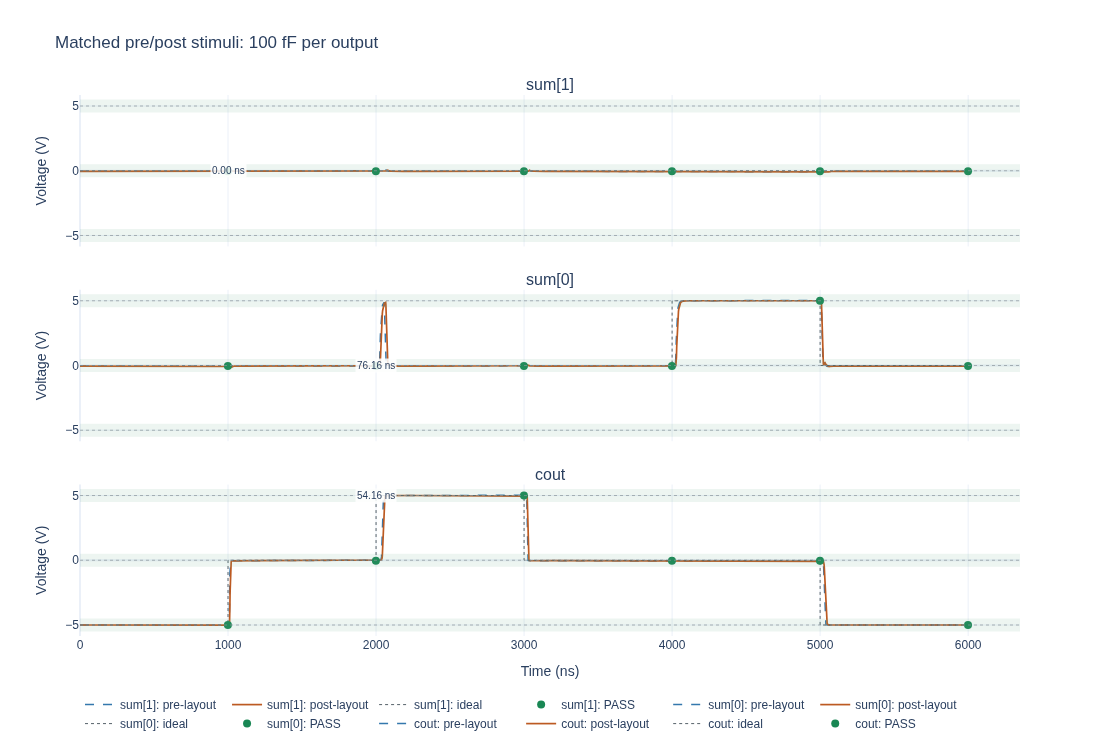

Output,Pre max settling (ns),Post max settling (ns)
sum[1],0.0,0.0
sum[0],65.24373390724975,76.15874684164314
cout,45.04636295948995,54.16301919392655


Wire-C assumptions: Estimated substrate C only: SiO2 epsilon_r=3.9, effective M1/M2 heights 1/2 um, fringe=0.02 fF/um perimeter. Assumed, not PDK calibrated. Reviewed OS00 rev1.1 p5 (no parasitic extraction), OS04 p7 and model libraries; the ESD M1-M2 overlap rule is not a metal-to-substrate coefficient. No coupling, shielding, via C or signal wire R; not signoff PEX.


In [12]:
pre = cache.run("adder2-pre", {"net":net.to_json(),"vectors":vectors,"load":LOAD_F,
                             "hold":HOLD_S,"step":STEP_S,"edge":EDGE_S,"temperature_c":TEMP_C}, lambda:
    net.simulate(vectors, load=LOAD_F, expected=adder_reference, hold_s=HOLD_S,
                 step_s=STEP_S, edge_s=EDGE_S, temperature_c=TEMP_C, timeout=180))
assert pre["measurements"]["passed"]
assert pre["stimulus"]["vectors"] == demo["stimulus"]["vectors"]
assert pre["stimulus"]["hold_s"] == demo["stimulus"]["hold_s"]
assert pre["stimulus"]["step_s"] == demo["stimulus"]["step_s"]
show(waveform_figure(demo, outputs, pre=pre, title=f"Matched pre/post stimuli: {LOAD_F*1e15:g} fF per output"))
table([["Output", "Pre max settling (ns)", "Post max settling (ns)"]]+[
    [p, pre["measurements"]["max_settling_s"][p]*1e9,
     demo["measurements"]["max_settling_s"][p]*1e9] for p in outputs])
print("Wire-C assumptions:", demo["capacitance"]["assumptions"])
if EXTENDED:
    for load in [10e-15,1e-12]:
        loaded = cache.run(f"adder2-load-{load:g}", {"vectors":vectors,"load":load}, lambda:
            lay.extract().simulate(vectors, load=load, expected=adder_reference,
                                   hold_s=2e-6, step_s=2e-9, timeout=180))
        assert loaded["measurements"]["passed"], loaded["measurements"]
        print(load, loaded["measurements"]["passed"], loaded["measurements"]["max_settling_s"])


The next loop regenerates all shared designs from committed HDL and cell views;
it consumes no pre-existing `build/` results. SIM supplies the vector plans and
independent radix-arithmetic oracles. Small circuits visit every input state;
the larger adder uses labeled carry assertion/release, overflow and cancellation
cases. Neither sequence exhausts directed transitions. Each physical result is
checked before matched pre/post simulation. Maxima can occur on different
transitions; the last timing column compares each transition with itself.
Sub-timestep differences do not establish a speedup.


Running: four-adder4


Running: four-full_add


Running: four-mac1


Running: four-mul1


Design,Die (µm),Aspect,Utilization,DRC / LVS,Input states visited / possible,Post max error (mV),Rail deviation / zero shift (mV)
adder4,"[1740.0, 1590.0]",1.0943396226415094,0.4557449577098243,"[True, True]",18 / 19683,43.3398017062648,"[13.541582088762993, 1.8223931066398968]"
full_add,"[792.0, 702.0]",1.1282051282051282,0.5669515669515669,"[True, True]",27 / 27,43.33979683633803,"[7.269825933816421, 1.3686473004721478]"
mac1,"[804.0, 1038.0]",1.291044776119403,0.5143645932188767,"[True, True]",81 / 81,43.446458054704344,"[9.924680741586478, 1.4396704142654038]"
mul1,"[372.0, 366.0]",1.0163934426229508,0.523532522474881,"[True, True]",9 / 9,100.89105145212216,"[2.1743334189014973, 0.5690895635832582]"


Design,Output,Pre max (ns),Post max (ns),Largest same-transition change (ns)
adder4,sum[3],202.55427387975215,201.813103382441,0.0
adder4,sum[2],153.38103449126567,152.80792872571962,0.0
adder4,sum[1],123.06468724570144,122.15267579002746,0.0
adder4,sum[0],123.72922723794089,122.72890308267172,30.383342908625462
adder4,cout,192.73512903063394,191.644218934504,0.0
full_add,sum,100.5723006395906,109.84424492181513,9.272243647878627
full_add,cout,90.6088673999551,99.90947634968798,9.30060894973288
mac1,sum,132.25106173848124,144.00613469404126,13.152257507154271
mac1,cout,122.5019137852323,135.97201874312825,13.61837917640481
mac1,and_out,13.301397379081369,16.03354491834302,3.047058380177225


Shared load (fF),10.0
Hold / max step (ns),"[500.0, 2.0]"
Input plan labels,"{'adder4': ['zero', 'positive_propagate_setup', 'positive_carry_through_all_four_digits', 'positive_carry_release_through_all_four_digits', 'negative_propagate_setup', 'negative_carry_through_all_four_digits', 'negative_carry_release_through_all_four_digits', 'positive_overflow', 'negative_overflow', 'opposite_operands', 'alternating', 'alternating_reverse', 'positive_digit_0', 'negative_digit_0', 'positive_digit_1', 'negative_digit_1', 'positive_digit_2', 'negative_digit_2', 'positive_digit_3', 'negative_digit_3'], 'full_add': ['exhaustive_0', 'exhaustive_1', 'exhaustive_2', 'exhaustive_3', 'exhaustive_4', 'exhaustive_5', 'exhaustive_6', 'exhaustive_7', 'exhaustive_8', 'exhaustive_9', 'exhaustive_10', 'exhaustive_11', 'exhaustive_12', 'exhaustive_13', 'exhaustive_14', 'exhaustive_15', 'exhaustive_16', 'exhaustive_17', 'exhaustive_18', 'exhaustive_19', 'exhaustive_20', 'exhaustive_21', 'exhaustive_22', 'exhaustive_23', 'exhaustive_24', 'exhaustive_25', 'exhaustive_26'], 'mac1': ['exhaustive_0', 'exhaustive_1', 'exhaustive_2', 'exhaustive_3', 'exhaustive_4', 'exhaustive_5', 'exhaustive_6', 'exhaustive_7', 'exhaustive_8', 'exhaustive_9', 'exhaustive_10', 'exhaustive_11', 'exhaustive_12', 'exhaustive_13', 'exhaustive_14', 'exhaustive_15', 'exhaustive_16', 'exhaustive_17', 'exhaustive_18', 'exhaustive_19', 'exhaustive_20', 'exhaustive_21', 'exhaustive_22', 'exhaustive_23', 'exhaustive_24', 'exhaustive_25', 'exhaustive_26', 'exhaustive_27', 'exhaustive_28', 'exhaustive_29', 'exhaustive_30', 'exhaustive_31', 'exhaustive_32', 'exhaustive_33', 'exhaustive_34', 'exhaustive_35', 'exhaustive_36', 'exhaustive_37', 'exhaustive_38', 'exhaustive_39', 'exhaustive_40', 'exhaustive_41', 'exhaustive_42', 'exhaustive_43', 'exhaustive_44', 'exhaustive_45', 'exhaustive_46', 'exhaustive_47', 'exhaustive_48', 'exhaustive_49', 'exhaustive_50', 'exhaustive_51', 'exhaustive_52', 'exhaustive_53', 'exhaustive_54', 'exhaustive_55', 'exhaustive_56', 'exhaustive_57', 'exhaustive_58', 'exhaustive_59', 'exhaustive_60', 'exhaustive_61', 'exhaustive_62', 'exhaustive_63', 'exhaustive_64', 'exhaustive_65', 'exhaustive_66', 'exhaustive_67', 'exhaustive_68', 'exhaustive_69', 'exhaustive_70', 'exhaustive_71', 'exhaustive_72', 'exhaustive_73', 'exhaustive_74', 'exhaustive_75', 'exhaustive_76', 'exhaustive_77', 'exhaustive_78', 'exhaustive_79', 'exhaustive_80'], 'mul1': ['exhaustive_0', 'exhaustive_1', 'exhaustive_2', 'exhaustive_3', 'exhaustive_4', 'exhaustive_5', 'exhaustive_6', 'exhaustive_7', 'exhaustive_8']}"


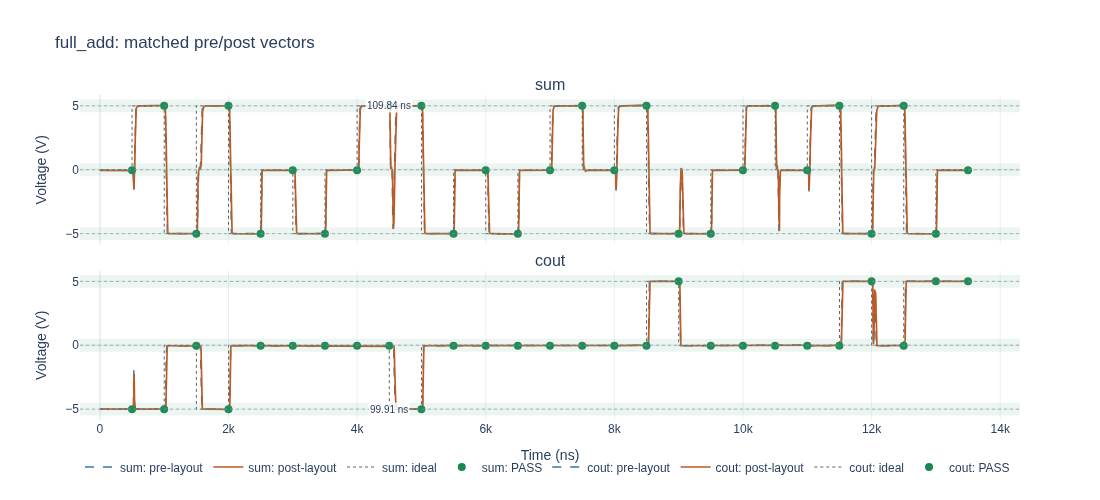

Wire-C assumptions: Estimated substrate C only: SiO2 epsilon_r=3.9, effective M1/M2 heights 1/2 um, fringe=0.02 fF/um perimeter. Assumed, not PDK calibrated. Reviewed OS00 rev1.1 p5 (no parasitic extraction), OS04 p7 and model libraries; the ESD M1-M2 overlap rule is not a metal-to-substrate coefficient. No coupling, shielding, via C or signal wire R; not signoff PEX.
IR assumptions (separate from ideal-rail SPICE): Constant nominal-bias cell currents; centerline sheet-R network. Default metal sheet R=0.05 ohm/square and via R=0.05 ohm are assumed, not PDK characterized; no package R, self-heating or voltage-dependent current iteration. OS00 p9 resistor sheet values do not apply to metal; no metal/TC/contact resistance found in the open PDFs/models. Zero shift assumes equal divider conductances.


In [13]:
from tritflow.sim.postlayout import representative_vectors, arithmetic_oracle
FOUR_DESIGN_LOAD_F, FOUR_DESIGN_HOLD_S, FOUR_DESIGN_STEP_S = 10e-15, 500e-9, 2e-9
four_results = {}
physical_rows = [["Design", "Die (µm)", "Aspect", "Utilization", "DRC / LVS", "Input states visited / possible",
                  "Post max error (mV)", "Rail deviation / zero shift (mV)"]]
timing_rows = [["Design", "Output", "Pre max (ns)", "Post max (ns)", "Largest same-transition change (ns)"]]
for name, source_name, params in [("adder4","adder",{"N":4}), ("full_add","full_add",{}),
                                  ("mac1","mac1",{}), ("mul1","mul1",{})]:
    mapped = flow.load(ROOT/f"examples/{source_name}.tv", source_name, params).synthesize(name=name)
    pins = [p.name for p in mapped.ports if p.dir == "input"]
    planned, labels = representative_vectors(name, pins)
    oracle = arithmetic_oracle(name, pins)
    directory = BUILD/"four_designs"/name
    result = cache.run(f"four-{name}", {"net":mapped.to_json(),"vectors":planned,"labels":labels,
                       "expected":[oracle(v) for v in planned],"load_f":FOUR_DESIGN_LOAD_F,
                       "hold_s":FOUR_DESIGN_HOLD_S,"step_s":FOUR_DESIGN_STEP_S,
                       "rows":None,"anneal_steps":600,"seed":0},
        lambda: complete_design(mapped,directory,planned,oracle,load_f=FOUR_DESIGN_LOAD_F,
                   hold_s=FOUR_DESIGN_HOLD_S,step_s=FOUR_DESIGN_STEP_S),
        artifacts=lambda r: experiment_artifacts(r,directory,name))
    assert_experiment(result)
    assert result["post"]["stimulus"]["vectors"] == list(map(tuple,planned))
    stats, ir = result["stats"], result["ir"]
    rail = max(abs(v) for c in ir["cells"].values() for v in c["rail_deviation_v"].values())
    zero = max(abs(c["zero_level_shift_v"]) for c in ir["cells"].values() if c["zero_level_shift_v"] is not None)
    physical_rows.append([name,stats["die_size_um"],max(stats["die_size_um"])/min(stats["die_size_um"]),
                          stats["utilization"],[result["drc"]["clean"],result["lvs"]["matched"]],
                          f"{len(set(planned))} / {3**len(pins)}",result["post"]["measurements"]["max_error_v"]*1e3,
                          [rail*1e3,zero*1e3]])
    before, after = [result[mode]["measurements"] for mode in ("pre","post")]
    for pin in after["max_settling_s"]:
        changes = [b["outputs"][pin]["settling_s"]-a["outputs"][pin]["settling_s"]
                   for a,b in zip(before["rows"][1:],after["rows"][1:],strict=True)]
        timing_rows.append([name,pin,before["max_settling_s"][pin]*1e9,after["max_settling_s"][pin]*1e9,
                            max(changes)*1e9])
    four_results[name] = result
table(physical_rows)
table(timing_rows)
table([["Shared load (fF)",FOUR_DESIGN_LOAD_F*1e15], ["Hold / max step (ns)",
       [FOUR_DESIGN_HOLD_S*1e9,FOUR_DESIGN_STEP_S*1e9]],
       ["Input plan labels", {name:representative_vectors(name,
          r["post"]["stimulus"]["inputs"])[1] for name,r in four_results.items()}]])
FOUR_DESIGN_VIEW = "full_add"  # switch to adder4, mac1 or mul1
viewed = four_results[FOUR_DESIGN_VIEW]
show(waveform_figure(viewed["post"],pre=viewed["pre"],title=f"{FOUR_DESIGN_VIEW}: matched pre/post vectors"))
print("Wire-C assumptions:", viewed["capacitance"]["assumptions"])
print("IR assumptions (separate from ideal-rail SPICE):", viewed["ir"]["assumptions"])


**SIM publication slots — width scaling and load boundary:** the following cell
reads `results/adder_scaling.json` and `results/full_add_load_sweep.json` when
SIM publishes them. Missing data stays a TODO; no interpolated or invented
measurements fill the gap. The precomputed readers/figures are fast. Producing
the full matrix or refining a failing load is an opt-in experiment, outside
default Run all: `run_scaling(sizes=range(1,7), *, jobs=1, destination=..., **kwargs)`
and `sweep_output_load(directory, *, loads_f=..., hold_s=500e-9, step_s=2e-9,
relative_resolution=.02, absolute_resolution_f=50e-15, timeout=600, destination=...)`.
The latter reports the first observed failure on its stated sequence/window;
it is not a universal or PVT-qualified maximum capacitance. Failed/unsettled
points retain their flags and null delays.


In [14]:
from tritflow.sim.scaling import load_scaling
from tritflow.sim.load_sweep import load_sweep_results
from tritflow.viz.scaling import scaling_figure, load_sweep_figure
for filename, loader, figure in [("adder_scaling.json",load_scaling,scaling_figure),
                                  ("full_add_load_sweep.json",load_sweep_results,load_sweep_figure)]:
    published = ROOT/"results"/filename
    if not published.is_file():
        print(f"TODO SIM: publish results/{filename}; no scaling/boundary result claimed")
        continue
    result = loader(published)
    try:
        records = result["rows"] if filename == "adder_scaling.json" else [result]
        for record in records:
            verify_publication_sources(record,ROOT,PDK_ROOT)
    except RuntimeError as error:
        print(f"TODO SIM: refresh results/{filename}: {error}; no current result claimed")
        continue
    print("Published experiment:", filename, result.get("coverage",result.get("scope")))
    print("Limits / conditions:",result.get("limits",result.get("conditions")))
    if filename == "adder_scaling.json":
        table([["Width", "Recorded state", "PASS", "Error"]]+
              [[r["n"],r["state"],r["passed"],r["error"]] for r in result["rows"]])
    else:
        table([["Measured boundary (F)",result["boundary"]], ["Boundary found",result["boundary_found"]],
               ["Outputs / input-state count",[result["outputs"],len(result["vectors"])]]])
    show(figure(result))


TODO SIM: refresh results/adder_scaling.json: published result is stale relative to $TRITFLOW_ROOT/tritflow/__init__.py; no current result claimed
TODO SIM: refresh results/full_add_load_sweep.json: published result is stale relative to $TRITFLOW_ROOT/tritflow/__init__.py; no current result claimed


## 8. Your circuit: choose, edit and check

Choose a catalog key below: sign, signed two-trit comparison, exact two-trit
multiplication, or a min/max sorter. Each source has an independent integer
oracle. The generated table checks every input against both source and mapped
logic. The selected circuit then runs real P&R, DRC/LVS and extracted simulation
through the same chain. Editing HDL can intentionally fail the oracle; update
the mathematical specification only when you intend to change the function.
Initial internal-node Newton guesses use mapped trits and strict-LVS net
correspondence. They avoid nonphysical model operating-point roots; `.nodeset`
is unconstrained during the transient, with no `.ic`/`uic` or circuit changes.
Output acceptance still uses the independent arithmetic oracle. The actual
guesses are displayed with the result.

`~`, `&`, `|` and `nany` retain their ternary meanings. Here is a deliberately
broken expression, caught before any physical work. Located errors identify
the filename/line/column and the supported replacement operators.


In [15]:
from tritflow.hdl import HDLError
broken = """module broken(input trit a,b,output trit y);
 assign y = a + b;
endmodule"""
try:
    flow.loads(broken,"broken",filename="your_circuit.tv")
except HDLError as error:
    print(error)
    print("Repair: use gates for signal arithmetic; e.g. nany(a,b) gives the negative saturated sum.")
else:
    raise AssertionError("unsupported signal arithmetic must be rejected")


your_circuit.tv:2:13: arithmetic/comparison on trits is unsupported; use ~, &, |, nany and sized trit literals
Repair: use gates for signal arithmetic; e.g. nany(a,b) gives the negative saturated sum.


Choice,Specification
sign,One trit's sign and its opposite
compare2,Signed comparison of two two-trit integers
mul2,Exact two-trit by two-trit product in four trits
minmax,Sort two scalar trits into ascending order


// & and | are min/max on -1 < 0 < +1, not bitwise Boolean operators.
module minmax(input trit a, b, output trit lo, hi);
  assign lo = a & b;
  assign hi = a | b;
endmodule



Vector,ainput,binput,looutput,hioutput
1,-1,-1,-1,-1
2,-1,0,-1,0
3,-1,+1,-1,+1
4,0,-1,-1,0
5,0,0,0,0
6,0,+1,0,+1
7,+1,-1,-1,+1
8,+1,0,0,+1
9,+1,+1,+1,+1


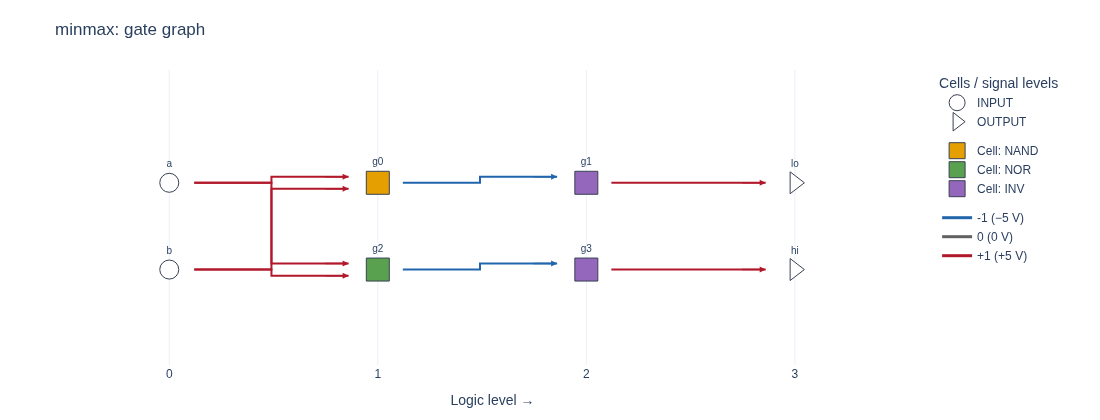

Running: your-minmax


Independent arithmetic input states,9
Physical results,"{'die_size_um': [336.0, 366.0], 'die_area_um2': 122976.0, 'wirelength_um': {'M1': 1194.0, 'M2': 1254.0}, 'via_count': 30, 'power_via_count': 32, 'utilization': 0.5409836065573771, 'instance_count': 4, 'row_count': 2, 'net_count': 6, 'spans_per_row': 1, 'channel_tracks': 4, 'aspect_ratio': 1.0892857142857142, 'anneal_steps': 600, 'routed_nets': 6, 'library_mock': False, 'max_supply_drop_v': 0.0021052563772356843, 'bypass_tracks_per_side': 0, 'hpwl_before_um': 932.0, 'hpwl_after_um': 416.0, 'hpwl_improvement_pct': 55.36480686695279, 'runtime_s': {'placement': 0.015570094008580782, 'routing': 0.006612750003114343, 'export_and_verification': 1.7051622799917823, 'total': 1.7273451240034774}}"
DRC clean / LVS matched,"[True, True]"
Initial Newton guesses (V),"{'pre': {'xdut._n0': 5.0, 'xdut._n2': 5.0}, 'post': {'xdut.n_ex_I7': 5.0, 'xdut.n_ex_I6': 5.0}}"


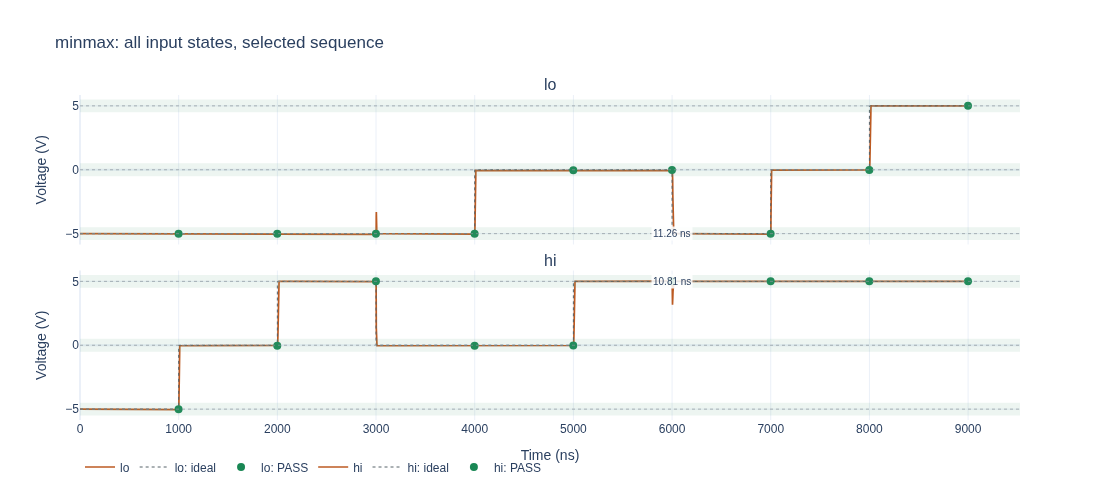

In [16]:
from examples.curated import DESIGNS
from tritflow.synth import evaluate_netlist
CHOICE = os.environ.get("TRITFLOW_CIRCUIT", "minmax")  # sign | compare2 | mul2 | minmax
table([["Choice", "Specification"]]+[[key,item.description] for key,item in DESIGNS.items()])
example = DESIGNS[CHOICE]
source = example.path.read_text()  # edit this string, or choose another catalog entry
print(source)
# Stage includes beside the edited text, preserving the committed source files.
custom_circuit = load_edited(example,source,BUILD/"your_circuit"/"source"/example.top)
custom = custom_circuit.synthesize()
truth = custom_circuit.truth_table()
pins = custom_circuit.design.inputs
planned = list(zip(*(truth[p] for p in pins)))
oracle = example.oracle(pins)
mapped_truth = evaluate_netlist(custom,{p:truth[p] for p in pins})
for i, vector in enumerate(planned):
    expected = oracle(vector)
    assert {p:int(truth[p][i]) for p in expected} == expected
    assert {p:int(mapped_truth[p][i]) for p in expected} == expected
display(truth_table_html(custom,max_rows=len(planned)))
show(color_nets(custom,dict(zip(pins,planned[-1]))))
custom_out = BUILD/"your_circuit"/example.top
custom_result = cache.run(f"your-{CHOICE}", {"source":source,"net":custom.to_json(),"vectors":planned,
                         "expected":[oracle(v) for v in planned],"load_f":10e-15,"hold_s":1e-6,
                         "step_s":2e-9,"rows":None,"anneal_steps":600,"seed":0,"initialize_internal":True},
    lambda: complete_design(custom,custom_out,planned,oracle,hold_s=1e-6,initialize_internal=True),
    artifacts=lambda r: experiment_artifacts(r,custom_out,example.top))
assert_experiment(custom_result)
assert {tuple(row["input_trits"]) for row in custom_result["post"]["measurements"]["rows"]} == set(planned)
table([["Independent arithmetic input states",len(planned)], ["Physical results",custom_result["stats"]],
       ["DRC clean / LVS matched",[custom_result["drc"]["clean"],custom_result["lvs"]["matched"]]],
       ["Initial Newton guesses (V)",custom_result["initial_nodeset_v"]]])
show(waveform_figure(custom_result["post"],title=f"{CHOICE}: all input states, selected sequence"))


## 9. Connect the model to a future measurement

The exported drawings document the historical reference topology, not measured
silicon performance. Record actual device/package identity, measured supply
voltages, temperature, probe capacitance and stimulus skew. Compare
DC levels and final band-entry times with matched loads and stimulus edges.
Repeat with supply/temperature variation, then revise model assumptions from
measured discrepancies. The generated core is not a padframe or ESD-qualified
top, and nominal device simulation is not a lifetime qualification.

**TODO — integrator:** confirm the measurement schedule and hardware details;
replace draft placeholders, publish the `colab-v0` tag, and run this exact
notebook in a clean Colab runtime before submission. Record cold/warm runtimes
and keep total default Run all near ten minutes.

Sources: [OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um),
[reference cells and arithmetic](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic),
[official KLayout packages](https://www.klayout.de/build.html).
The setup pins the PDK commit and verifies SHA-256 archive/package downloads.


In [17]:
print("Cache stages:", cache.events)
print(f"Run time including setup: {time.monotonic()-started:.1f} s")
print("Artifacts:", BUILD)


Cache stages: [('adder2-complete', 'run'), ('adder2-raster', 'run'), ('nany-dc', 'run'), ('adder2-pre', 'run'), ('four-adder4', 'run'), ('four-full_add', 'run'), ('four-mac1', 'run'), ('four-mul1', 'run'), ('your-minmax', 'run')]
Run time including setup: 787.7 s
Artifacts: $OUTPUTDIR/flow
